# TP3 - Clasificación de uso del suelo con CNNs (EuroSAT RGB)
### Tecnología Digital VI - Inteligencia Artificial

**Integrantes:** Manuel Milde, Luciano Pozzoli

Este notebook resuelve el TP3: clasificar el **uso del suelo** de recortes de
imágenes satelitales Sentinel-2 (dataset **EuroSAT**, versión **RGB**) en
**10 clases balanceadas** (`AnnualCrop`, `Forest`, `HerbaceousVegetation`,
`Highway`, `Industrial`, `Pasture`, `PermanentCrop`, `Residential`, `River`,
`SeaLake`) usando Redes Neuronales Convolucionales en **PyTorch**.

Estructura del notebook:

1. Setup y carga de datos
2. Análisis Exploratorio (EDA)
3. Pipeline de datos y Data Augmentation
4. Arquitectura custom (CNN desde cero)
5. Entrenamiento desde cero + monitoreo de métricas y de gradientes
6. Evaluación en test y análisis de errores (matriz de confusión)
7. Espacio latente (PCA / t-SNE / UMAP)
8. Transfer Learning con ResNet18 preentrenada en ImageNet
9. Comparación: CNN custom vs Transfer Learning
10. Conclusiones finales

La lógica reutilizable (datos, augmentation, modelos, loop de entrenamiento,
monitor de gradientes, evaluación y espacio latente) vive en
`src/eurosat_cnn/` — este notebook la importa y se enfoca en el análisis,
los resultados y las decisiones tomadas.

## 1. Setup y carga de datos

**Dónde correrlo:** se recomienda un entorno con GPU (Google Colab o un
notebook de Kaggle). En CPU funciona, pero el entrenamiento completo tarda
bastante más.

**Descarga del dataset** (https://www.kaggle.com/datasets/apollo2506/eurosat-dataset):

- **Kaggle notebook:** agregar el dataset con *Add Input* y setear
  `EUROSAT_DIR = "/kaggle/input/eurosat-dataset"`.
- **Colab / local:** con la API de Kaggle (necesita `kaggle.json`):
  ```bash
  pip install kaggle
  kaggle datasets download -d apollo2506/eurosat-dataset -p data/raw --unzip
  ```

El loader (`data.load_splits`) busca automáticamente la carpeta con las 10
subcarpetas de clase (ignora la versión multiespectral `EuroSATallBands`).
Si encuentra los CSVs `train.csv` / `validation.csv` / `test.csv` del dataset
de Kaggle usa esa partición; si no, hace un split estratificado 70/15/15
reproducible.

In [4]:
# --- Solo en Colab: descomentar para clonar/subir el proyecto e instalar deps ---
# !pip install -q umap-learn kaggle
# from google.colab import files; files.upload()  # subir kaggle.json
# !mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
# !kaggle datasets download -d apollo2506/eurosat-dataset -p data/raw --unzip

In [5]:
import torch
print(torch.__version__, torch.cuda.is_available())

2.14.1+cu126 True


In [6]:
import os
import sys
import time
from pathlib import Path

# Permite importar el paquete src/eurosat_cnn desde el notebook
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

# Ruta al dataset (sobreescribir si está en otro lado, ej. en Kaggle)
# os.environ["EUROSAT_DIR"] = "/kaggle/input/eurosat-dataset"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from torch import nn

from eurosat_cnn import config, data
from eurosat_cnn.utils import set_seed, get_device, count_params
from eurosat_cnn.models import EuroSATCNN, build_resnet18, resnet_param_groups
from eurosat_cnn.training import fit
from eurosat_cnn.gradients import GradientMonitor
from eurosat_cnn.evaluate import (
    predict, metrics_summary, report_df, plot_confusion_matrix,
    top_confusions, plot_misclassified,
)
from eurosat_cnn.latent import (
    extract_features, raw_pixels, project, separability_scores,
    plot_embeddings, plot_embedding_3d,
)
from eurosat_cnn.plotting import (
    plot_history, plot_comparison, epochs_to_reach,
    show_batch_by_class, show_augmentations,
)

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
config.MODELS_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = config.RANDOM_STATE
set_seed(RANDOM_STATE)
DEVICE = get_device()
print("Device:", DEVICE, "| PyTorch", torch.__version__)

Device: cuda | PyTorch 2.14.1+cu126


In [7]:
# --- Hiperparámetros del experimento ---------------------------------------
# SMOKE_TEST=True corre todo con muy pocos datos/épocas: sirve solo para
# verificar que el pipeline funciona de punta a punta (NO para reportar).
SMOKE_TEST = os.environ.get("EUROSAT_SMOKE") == "1"

EPOCHS_CUSTOM = 2 if SMOKE_TEST else 30   # CNN desde cero
EPOCHS_TL = 2 if SMOKE_TEST else 10       # ResNet18 (converge mucho antes)
GRAD_MONITOR_EPOCHS = 2 if SMOKE_TEST else 3
MAX_PER_CLASS = 30 if SMOKE_TEST else None
PRETRAINED = not SMOKE_TEST               # pesos de ImageNet (requiere internet)
TL_IMG_SIZE = 64                          # 224 = resolución de ImageNet (más lento)
BATCH_SIZE = 32 if SMOKE_TEST else config.BATCH_SIZE

def savefig(fig, name):
    fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=130, bbox_inches="tight")

In [8]:
splits = data.load_splits(max_per_class=MAX_PER_CLASS)
splits["train"].head()

Dataset en C:\Users\ASUS\Documents\Universidad\TD6\TP3\tp3_eurosat\data\raw\EuroSAT (CSVs oficiales del dataset de Kaggle)
  train:  18900 imágenes
  val  :   5400 imágenes
  test :   2700 imágenes


,path,label,class_name
0,C:\Users\ASUS\Documents\Universidad\TD6\TP3\tp...,0,AnnualCrop
1,C:\Users\ASUS\Documents\Universidad\TD6\TP3\tp...,2,HerbaceousVegetation
2,C:\Users\ASUS\Documents\Universidad\TD6\TP3\tp...,6,PermanentCrop
3,C:\Users\ASUS\Documents\Universidad\TD6\TP3\tp...,4,Industrial
4,C:\Users\ASUS\Documents\Universidad\TD6\TP3\tp...,2,HerbaceousVegetation


## 2. Análisis Exploratorio (EDA)

Objetivo: verificar el balance de clases y la integridad de los splits,
mirar ejemplos de cada clase para anticipar qué pares van a ser difíciles de
distinguir, y calcular las estadísticas por canal para normalizar.

### 2.1 Distribución de clases por split

,train,val,test,total
class_name,,,,
AnnualCrop,2100,600,300,3000
Forest,2100,600,300,3000
HerbaceousVegetation,2100,600,300,3000
Highway,1750,500,250,2500
Industrial,1750,500,250,2500
Pasture,1400,400,200,2000
PermanentCrop,1750,500,250,2500
Residential,2100,600,300,3000
River,1750,500,250,2500


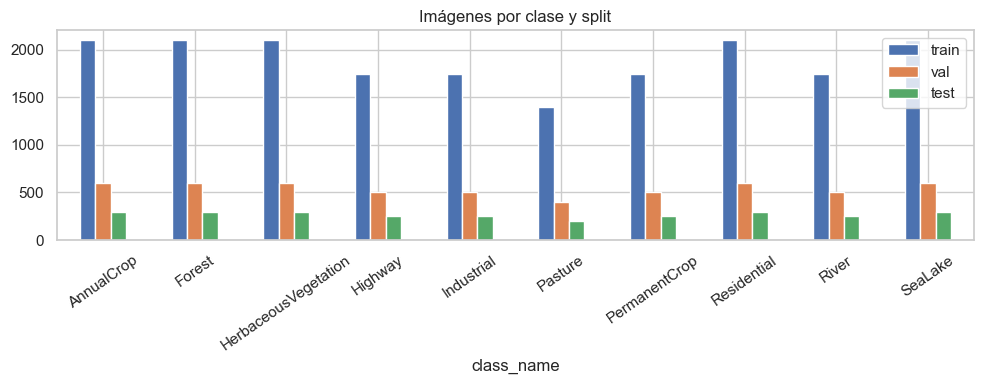

Intersección train∩val: 0 | train∩test: 0 | val∩test: 0


In [9]:
counts = pd.DataFrame({k: v["class_name"].value_counts() for k, v in splits.items()})
counts = counts.reindex(config.CLASSES)
counts["total"] = counts.sum(axis=1)
display(counts)

fig, ax = plt.subplots(figsize=(10, 4))
counts[["train", "val", "test"]].plot(kind="bar", ax=ax)
ax.set_title("Imágenes por clase y split")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout(); savefig(fig, "eda_clases"); plt.show()

# Chequeo de leakage: ninguna imagen debería estar en dos splits a la vez
paths = {k: set(v["path"]) for k, v in splits.items()}
print("Intersección train∩val:", len(paths["train"] & paths["val"]),
      "| train∩test:", len(paths["train"] & paths["test"]),
      "| val∩test:", len(paths["val"] & paths["test"]))

El dataset es **aproximadamente balanceado** (entre 2000 y 3000 imágenes por
clase en el EuroSAT completo; las clases con menos ejemplos son `Pasture`
—2000— e `Highway`/`Industrial`/`PermanentCrop`/`River` —2500—). Por eso
**accuracy** es una métrica razonable, pero igual reportamos **F1-macro** y
las métricas por clase para no esconder un mal desempeño en las clases más
chicas.

### 2.2 Ejemplos por clase y estadísticas por canal

Tamaño de imagen (C, H, W): (3, 64, 64)


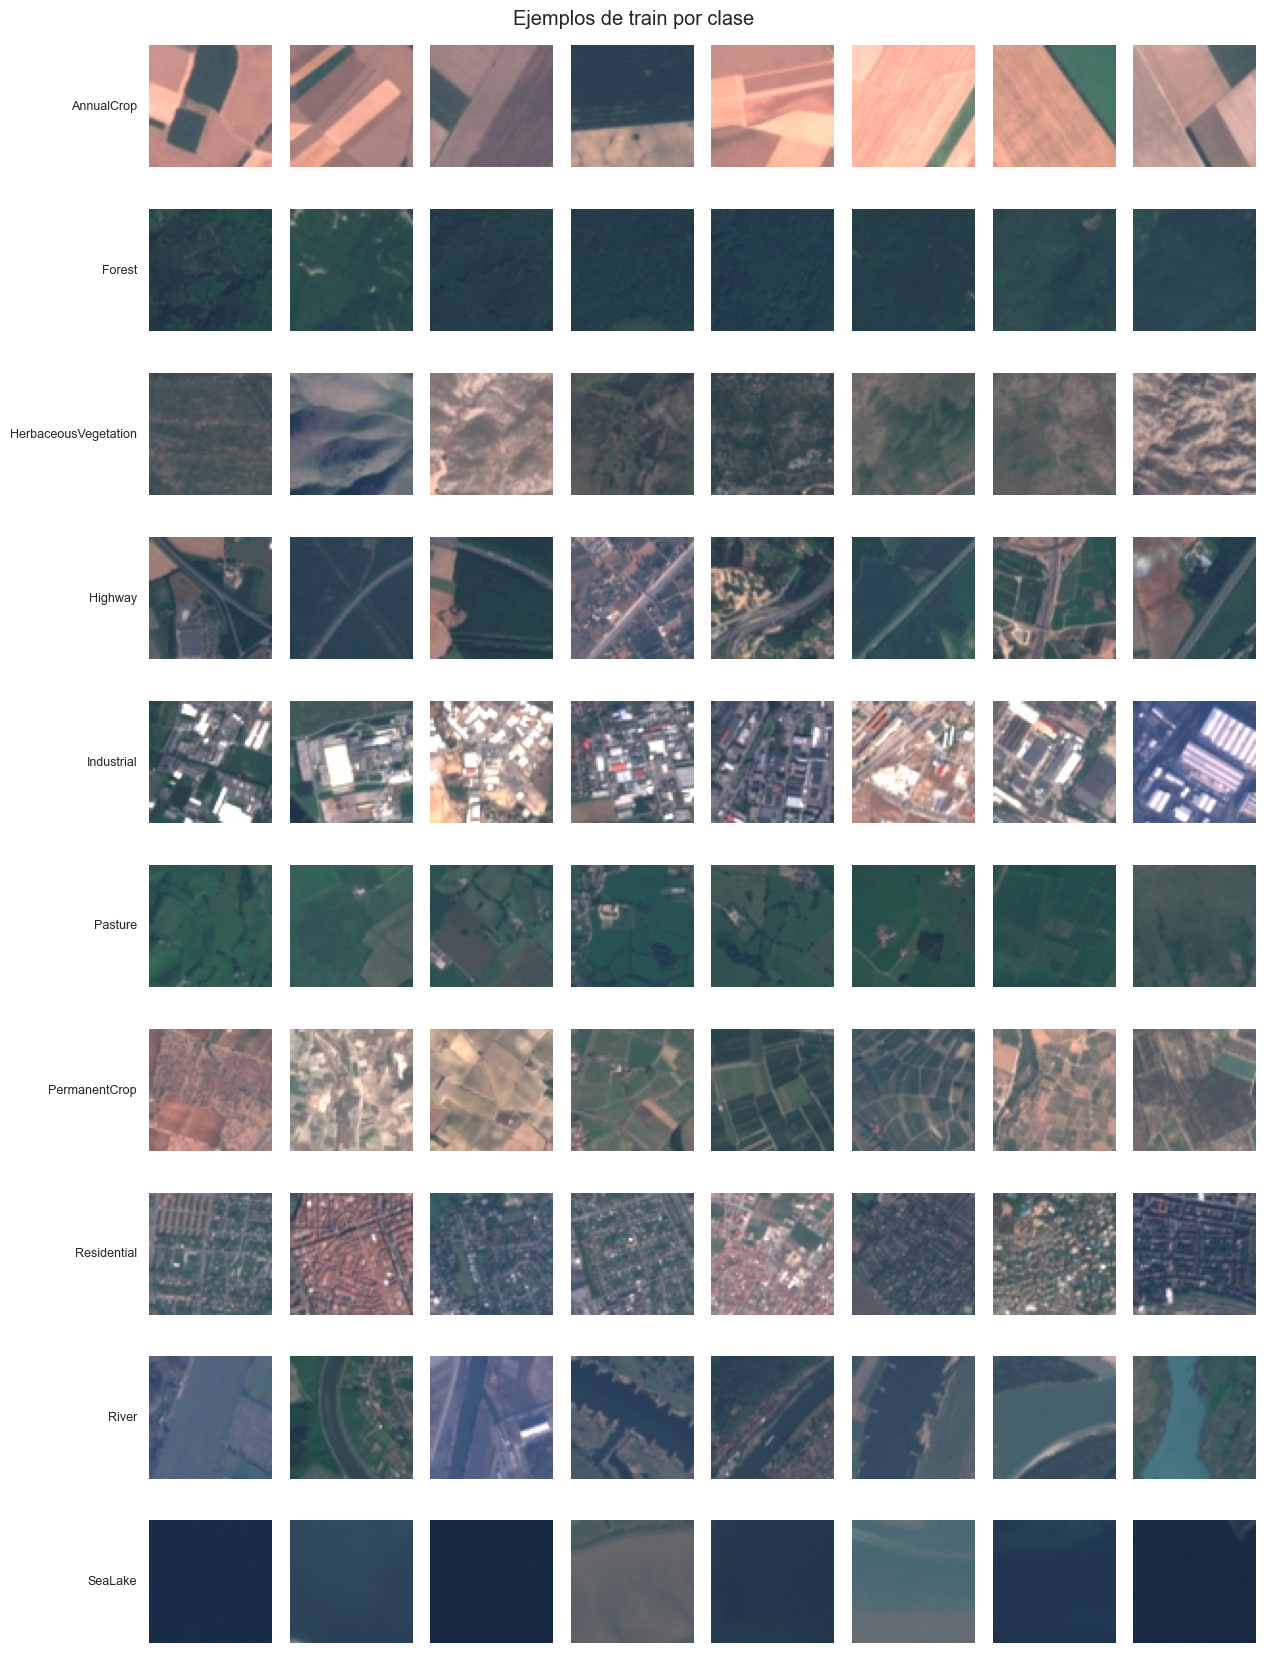

In [10]:
from torchvision import transforms as T

viz_ds = data.EuroSATDataset(splits["train"], T.ToTensor())
img0, _ = viz_ds[0]
print("Tamaño de imagen (C, H, W):", tuple(img0.shape))

fig = show_batch_by_class(viz_ds, splits["train"]["label"], (0, 0, 0), (1, 1, 1),
                          n_per_class=8, title="Ejemplos de train por clase")
savefig(fig, "eda_ejemplos"); plt.show()

In [11]:
# Media/desvío por canal sobre train (para normalizar la CNN custom).
# Para ResNet18 se usan las estadísticas de ImageNet, que son las que vio
# la red durante su preentrenamiento.
EUROSAT_MEAN, EUROSAT_STD = data.compute_mean_std(splits["train"])
print("Media RGB:", np.round(EUROSAT_MEAN, 4))
print("Std   RGB:", np.round(EUROSAT_STD, 4))

Media RGB: [0.3508 0.3844 0.4102]
Std   RGB: [0.2124 0.1428 0.1197]


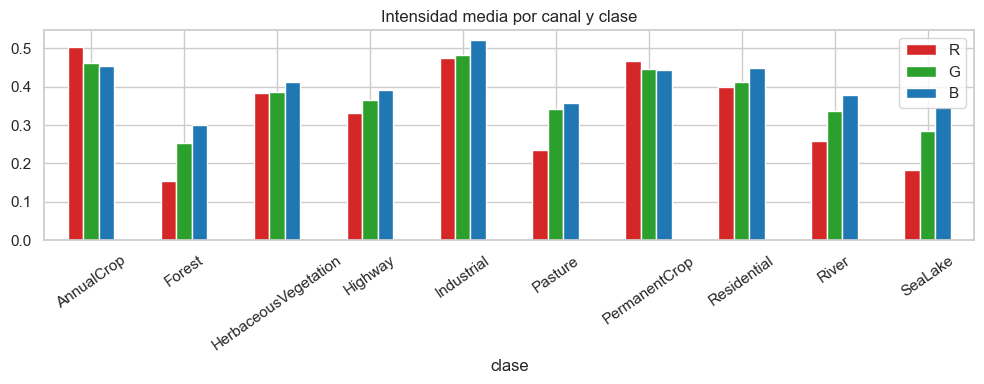

In [12]:
# Color medio por clase: ¿cuánta información trae solo el color?
rows = []
for c in config.CLASSES:
    sub = splits["train"][splits["train"]["class_name"] == c].sample(
        min(150, (splits["train"]["class_name"] == c).sum()), random_state=0)
    m = np.mean([viz_ds.transform(data.Image.open(p).convert("RGB")).mean((1, 2)).numpy()
                 for p in sub["path"]], axis=0)
    rows.append({"clase": c, "R": m[0], "G": m[1], "B": m[2]})
color_df = pd.DataFrame(rows).set_index("clase")

fig, ax = plt.subplots(figsize=(10, 4))
color_df.plot(kind="bar", color=["#d62728", "#2ca02c", "#1f77b4"], ax=ax)
ax.set_title("Intensidad media por canal y clase")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout(); savefig(fig, "eda_color_por_clase"); plt.show()

**Conclusiones del EDA:**

- **Partición:** se usaron los CSVs oficiales del dataset de Kaggle:
  18.900 imágenes de train, 5.400 de validación y 2.700 de test (70/20/10),
  estratificados y **sin imágenes repetidas entre splits** (intersecciones
  vacías → sin leakage).
- **Balance:** entre 2.000 (`Pasture`) y 3.000 imágenes por clase. Hay un
  desbalance leve (1,5× entre la clase más grande y la más chica), por lo
  que accuracy es representativa, pero igual reportamos F1-macro.
- **Color:** el gráfico de intensidad media por canal muestra que el color
  ya separa grupos de clases. `Forest`, `SeaLake`, `River` y `Pasture` son
  oscuras en rojo (la vegetación densa y el agua absorben el rojo), mientras
  que `AnnualCrop`, `PermanentCrop`, `Industrial` y `Residential` son
  claras y con los tres canales parecidos (suelo desnudo, techos). Al mismo
  tiempo, **`AnnualCrop` y `PermanentCrop` tienen un perfil de color casi
  idéntico**, y `HerbaceousVegetation` queda en el medio de todas: para
  separarlas la red tiene que apoyarse en la **textura y la geometría**
  (parcelas rectangulares, filas de plantas, manchas irregulares). Son las
  candidatas naturales a confundirse.
- `Highway` y `River` son estructuras lineales sobre fondo vegetal, y
  `Industrial` y `Residential` comparten superficies construidas: otros dos
  pares a vigilar.
- **Normalización:** media RGB de train = (0,351; 0,384; 0,410) y desvío =
  (0,212; 0,143; 0,120). Son distintas de las de ImageNet, por eso la CNN
  custom usa las propias y ResNet18 las de ImageNet.

## 3. Pipeline de datos y Data Augmentation

Las imágenes satelitales se toman en **vista cenital (nadir)**: no hay un
"arriba" o "abajo" canónico. Un campo de cultivo rotado 90° o espejado sigue
siendo exactamente la misma clase. Por eso las augmentations más pertinentes
son **geométricas e invariantes a la orientación** (implementadas en
`data.build_transforms`):

| Transformación | Justificación |
|---|---|
| `RandomHorizontalFlip` + `RandomVerticalFlip` | No hay orientación privilegiada en una imagen cenital. |
| `RandomRot90` (0/90/180/270°) | Igual que los flips; además, al ser múltiplos de 90° **no genera esquinas vacías** que haya que rellenar (a diferencia de una rotación arbitraria). Flips + rot90 cubren el grupo diédrico completo (8 orientaciones). |
| `RandomResizedCrop(scale=0.8-1)` | Robustez a pequeños desplazamientos y cambios de escala del recorte. Se mantiene suave porque la imagen es de solo 64×64. |
| `ColorJitter` suave (±10%) | Simula diferencias de iluminación, estación del año y atmósfera entre adquisiciones. Es **chico a propósito**: el color es muy informativo (agua vs. vegetación vs. suelo) y alterarlo mucho podría cambiar la semántica (ej. un pasto verde que "parezca" seco). |

**No** usamos augmentations que rompan la física de la imagen, como
rotaciones arbitrarias con relleno, *cutout* grandes o cambios de tono
(hue) fuertes. Validación y test **no** llevan augmentation (solo
normalización).

In [13]:
train_tf, eval_tf = data.build_transforms(EUROSAT_MEAN, EUROSAT_STD, augment=True)
print("Train transform:\n", train_tf)
print("\nEval transform:\n", eval_tf)

loaders = data.make_dataloaders(splits, train_tf, eval_tf, batch_size=BATCH_SIZE)
xb, yb = next(iter(loaders["train"]))
print("\nBatch de train:", tuple(xb.shape), "| labels:", tuple(yb.shape))

Train transform:
 Compose(
    RandomResizedCrop(size=(64, 64), scale=(0.8, 1.0), ratio=(0.9, 1.1), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRot90()
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=(0.9, 1.1), hue=None)
    ToTensor()
    Normalize(mean=(0.3507600724697113, 0.38443711400032043, 0.41020432114601135), std=(0.21240311861038208, 0.14279842376708984, 0.11968295276165009))
)

Eval transform:
 Compose(
    ToTensor()
    Normalize(mean=(0.3507600724697113, 0.38443711400032043, 0.41020432114601135), std=(0.21240311861038208, 0.14279842376708984, 0.11968295276165009))
)

Batch de train: (128, 3, 64, 64) | labels: (128,)


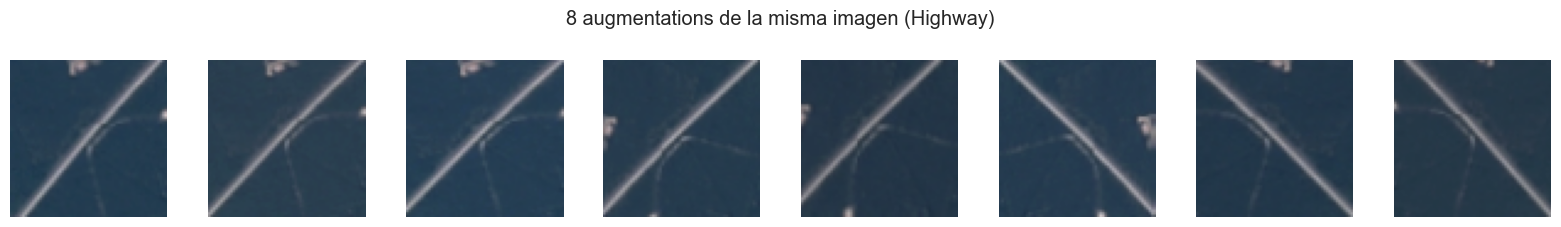

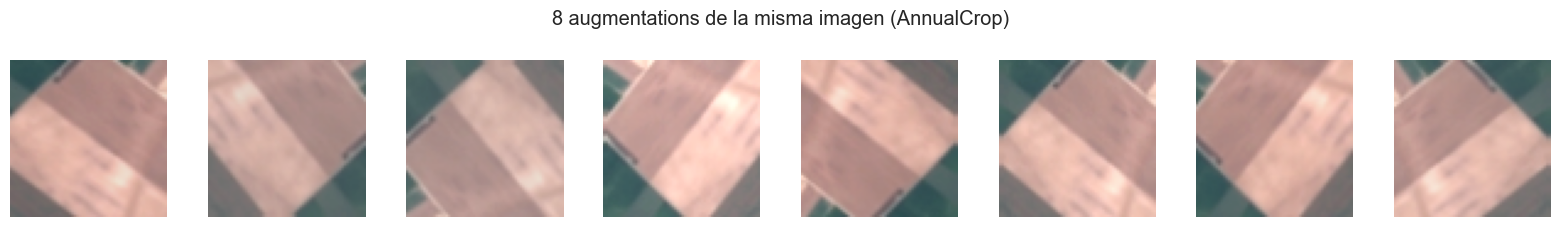

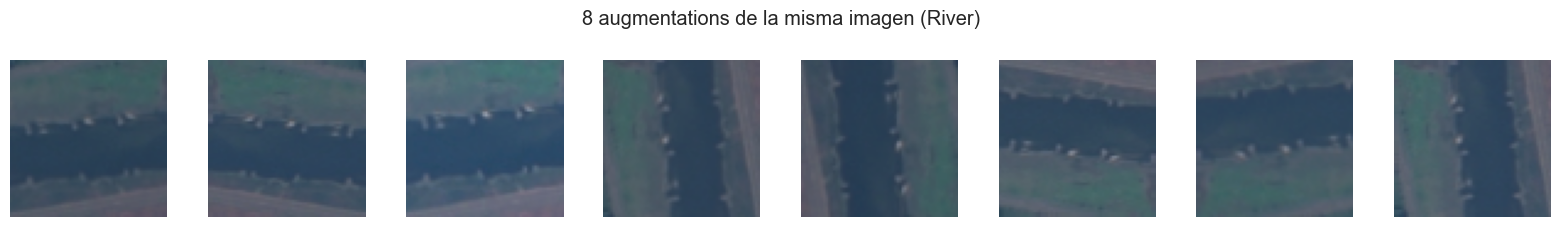

In [14]:
aug_ds = data.EuroSATDataset(splits["train"], train_tf)
for c in ["Highway", "AnnualCrop", "River"]:
    idx = int(np.where(splits["train"]["class_name"] == c)[0][0])
    fig = show_augmentations(aug_ds, idx, EUROSAT_MEAN, EUROSAT_STD, n=8,
                             title=f"8 augmentations de la misma imagen ({c})")
    savefig(fig, f"augment_{c}"); plt.show()

## 4. Arquitectura custom (CNN desde cero)

Diseñamos una CNN compacta estilo VGG (`models.EuroSATCNN`):

```
Input 3×64×64
 ├─ ConvBlock(3→32)    : [Conv3×3-BN-ReLU]×2 + MaxPool → 32×32×32
 ├─ ConvBlock(32→64)   : [Conv3×3-BN-ReLU]×2 + MaxPool → 64×16×16
 ├─ ConvBlock(64→128)  : [Conv3×3-BN-ReLU]×2 + MaxPool + Dropout2d → 128×8×8
 ├─ ConvBlock(128→256) : [Conv3×3-BN-ReLU]×2 + MaxPool + Dropout2d → 256×4×4
 ├─ Global Average Pooling → 256
 ├─ Dropout → Linear(256→128) → ReLU → Dropout     ← espacio latente (128-d)
 └─ Linear(128→10)                                  ← capa de clasificación
```

Decisiones de diseño:

- **Kernels 3×3 apilados**: dos convoluciones 3×3 tienen el mismo campo
  receptivo que una 5×5 con menos parámetros y una no-linealidad extra. Al
  final de la red el campo receptivo cubre todo el recorte de 64×64.
- **Duplicar canales al reducir la resolución a la mitad**: mantiene
  aproximadamente constante el costo por bloque y permite aprender cada vez
  más patrones (bordes → texturas → parcelas/estructuras).
- **Batch Normalization** después de cada convolución: estabiliza la
  distribución de las activaciones y la escala de los gradientes; es la
  principal defensa contra vanishing/exploding gradients (lo verificamos en
  la sección 5.2) y permite usar learning rates más altos.
- **Inicialización de He (Kaiming)**: diseñada para ReLU, preserva la
  varianza de activaciones y gradientes entre capas al inicio del
  entrenamiento.
- **Global Average Pooling** en lugar de `Flatten`: la clase de un recorte de
  EuroSAT depende de su textura global más que de la posición exacta de los
  objetos; GAP aporta esa invarianza y reduce mucho los parámetros de la
  parte densa (256×128 en vez de 4096×128).
- **Dropout** (en el bloque denso y `Dropout2d` en los últimos bloques
  convolucionales): regularización, el dataset (~19k imágenes de train) es
  chico para entrenar desde cero.

In [15]:
set_seed(RANDOM_STATE)
custom_model = EuroSATCNN().to(DEVICE)
print(custom_model)
print("\nParámetros:", count_params(custom_model))

with torch.no_grad():
    out = custom_model(xb[:4].to(DEVICE))
    emb = custom_model.forward_features(xb[:4].to(DEVICE))
print("Logits:", tuple(out.shape), "| Embedding latente:", tuple(emb.shape))

EuroSATCNN(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (7): Identity()
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1),

## 5. Entrenamiento desde cero

- **Loss:** Cross-Entropy (clasificación multiclase).
- **Optimizador:** AdamW (`lr=1e-3`, `weight_decay=5e-4`): Adam con weight
  decay desacoplado, buena opción por defecto para CNNs desde cero.
- **Scheduler:** `OneCycleLR` (warm-up y luego decaimiento coseno, se
  actualiza en cada batch): acelera la convergencia y ayuda a terminar en un
  mínimo más "plano".
- **Selección del modelo:** guardamos los pesos de la época con mejor
  **accuracy de validación** (`fit` hace el *checkpointing* en memoria). El
  test solo se usa una vez, al final.
- **Monitoreo de gradientes:** `GradientMonitor` registra la norma L2 del
  gradiente de cada capa (conv/linear) cada 10 batches durante las primeras
  épocas.

### 5.1 Loop de entrenamiento

In [16]:
set_seed(RANDOM_STATE)
custom_model = EuroSATCNN().to(DEVICE)
optimizer = torch.optim.AdamW(custom_model.parameters(), lr=1e-3, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=3e-3, epochs=EPOCHS_CUSTOM,
    steps_per_epoch=len(loaders["train"]), pct_start=0.2,
)
grad_monitor = GradientMonitor(custom_model, max_epochs=GRAD_MONITOR_EPOCHS,
                               log_every=1 if SMOKE_TEST else 10)

hist_custom, _ = fit(
    custom_model, loaders, optimizer, DEVICE, epochs=EPOCHS_CUSTOM,
    scheduler=scheduler, grad_monitor=grad_monitor, name="CNN custom",
)
torch.save(custom_model.state_dict(), config.MODELS_DIR / "cnn_custom_best.pt")
hist_custom.to_csv(config.OUTPUTS_DIR / "history_cnn_custom.csv", index=False)

[CNN custom] epoch  1/30 | train loss 1.3393 acc 0.5405 | val loss 0.9496 acc 0.6824 | lr 3.13e-04 | 82.8s
[CNN custom] epoch  2/30 | train loss 0.8552 acc 0.7072 | val loss 0.9868 acc 0.6954 | lr 8.41e-04 | 12.2s
[CNN custom] epoch  3/30 | train loss 0.7727 acc 0.7405 | val loss 0.7195 acc 0.7624 | lr 1.56e-03 | 12.4s
[CNN custom] epoch  4/30 | train loss 0.6587 acc 0.7836 | val loss 0.6192 acc 0.7831 | lr 2.28e-03 | 12.2s
[CNN custom] epoch  5/30 | train loss 0.5713 acc 0.8131 | val loss 0.6831 acc 0.7783 | lr 2.81e-03 | 12.2s
[CNN custom] epoch  6/30 | train loss 0.4908 acc 0.8432 | val loss 0.3896 acc 0.8726 | lr 3.00e-03 | 12.3s
[CNN custom] epoch  7/30 | train loss 0.4151 acc 0.8650 | val loss 1.0819 acc 0.7311 | lr 2.99e-03 | 12.2s
[CNN custom] epoch  8/30 | train loss 0.3808 acc 0.8744 | val loss 0.4113 acc 0.8670 | lr 2.95e-03 | 12.2s
[CNN custom] epoch  9/30 | train loss 0.3223 acc 0.8940 | val loss 0.8340 acc 0.7793 | lr 2.89e-03 | 12.3s
[CNN custom] epoch 10/30 | train loss

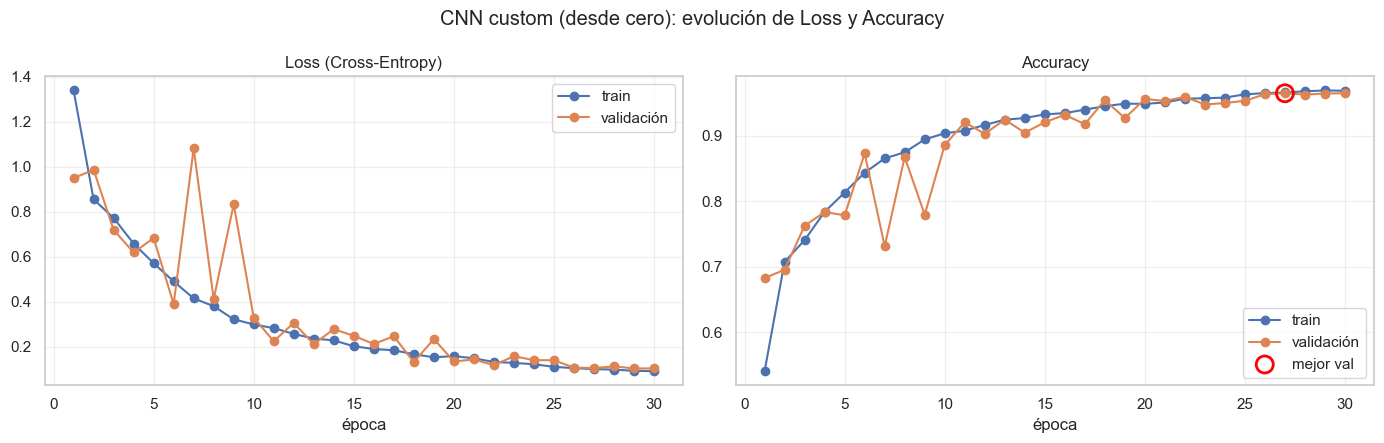

,epoch,train_loss,train_acc,val_loss,val_acc,lr,train_time_s,epoch_time_s,elapsed_s
25,26,0.1051,0.9647,0.1077,0.9630,0.0002,10.8563,12.4613,392.3688
26,27,0.1012,0.9656,0.1056,0.9644,0.0001,10.7926,12.3552,404.7280
27,28,0.0985,0.9675,0.1129,0.9624,0.0001,10.8763,12.4447,417.1765
28,29,0.0935,0.9687,0.1038,0.9641,0.0000,10.7649,12.3630,429.5398
29,30,0.0916,0.9683,0.1039,0.9644,0.0000,10.8939,12.4956,442.0358


In [17]:
fig = plot_history(hist_custom, "CNN custom (desde cero): evolución de Loss y Accuracy")
savefig(fig, "curvas_cnn_custom"); plt.show()
hist_custom.tail()

**Análisis de las curvas:**

- **Convergencia:** la CNN parte de 68,2% de accuracy de validación en la
  época 1, supera el **90% en la época 11** y el **95% en la 18**. La mejor
  accuracy de validación es **96,44%** (época 27).
- **Inestabilidad al principio:** entre las épocas 5 y 10 la validación
  oscila mucho (por ejemplo, en la época 7 la val loss salta a 1,08 y la
  accuracy cae a 73%). Coincide con el pico del learning rate de
  `OneCycleLR` (3e-3 entre las épocas 6 y 9): con pasos grandes los pesos
  saltan entre zonas del espacio de parámetros, y además las estadísticas
  móviles de BatchNorm (que se usan en `eval`) quedan desactualizadas
  respecto de pesos que cambian rápido. A partir de la época 10, cuando el
  LR empieza a bajar, las curvas se estabilizan y convergen suavemente.
- **Validación mejor que train al principio:** en las primeras épocas la
  accuracy de validación supera a la de train. Es lo esperable: train se
  mide *con* augmentation y *con* dropout activo, mientras que validación se
  mide con imágenes sin transformar y el modelo en modo `eval`.
- **Sin overfitting:** al final la loss de train (0,092) y la de validación
  (0,104) quedan prácticamente pegadas, igual que las accuracies (96,8% vs
  96,4%). La combinación de augmentation, dropout y weight decay regularizó
  bien la red; incluso habría margen para entrenar más épocas o usar un
  modelo algo más grande.

### 5.2 Monitoreo del flujo de gradientes

Para cada capa con pesos (convoluciones y lineales, ordenadas de la entrada a
la salida) graficamos:

1. la norma del gradiente a lo largo de los batches de las primeras épocas,
2. la norma media por capa (con su rango min-max),
3. la norma global del gradiente.

**¿Qué buscamos?**

- **Vanishing gradients:** las primeras capas con normas **órdenes de
  magnitud** menores que las últimas (o tendiendo a 0) → no aprenden.
- **Exploding gradients:** normas que crecen sin control, picos enormes o
  `NaN`/`Inf` → la loss diverge.
- **Flujo sano:** normas del mismo orden de magnitud entre capas (diferencias
  de 1-2 órdenes son normales), estables o decreciendo suavemente a medida
  que la loss baja.

c:\Users\ASUS\Documents\Universidad\TD6\TP3\tp3_eurosat\src\eurosat_cnn\gradients.py:183: UserWarning: Glyph 8711 (\N{NABLA}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\ASUS\Documents\Universidad\TD6\TP3\tp3_eurosat\src\eurosat_cnn\gradients.py:183: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_5988\215396079.py:15: UserWarning: Glyph 8711 (\N{NABLA}) missing from font(s) Arial.
  fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
C:\Users\ASUS\AppData\Local\Temp\ipykernel_5988\215396079.py:15: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
C:\Users\ASUS\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8711 (\N{NABLA}) missing fr

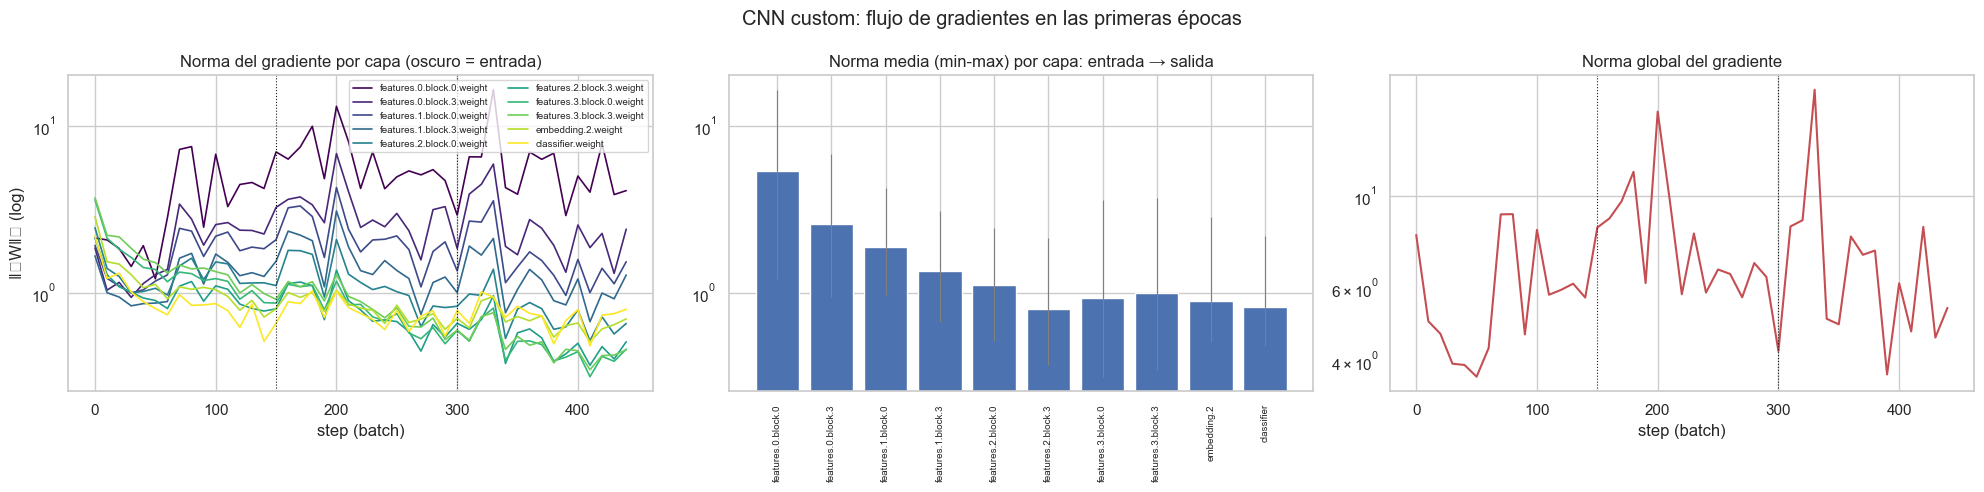

,grad_norm_mean,grad_norm_min,grad_norm_max,grad_to_weight_mean
layer,,,,
features.0.block.0.weight,5.3287,1.2155,16.4105,2.1697
features.0.block.3.weight,2.5813,0.9412,6.8180,0.3194
features.1.block.0.weight,1.8864,0.9673,4.2717,0.2348
features.1.block.3.weight,1.3496,0.6733,3.0901,0.1189
features.2.block.0.weight,1.1083,0.5173,2.4546,0.0974
features.2.block.3.weight,0.8061,0.3695,2.1418,0.0500
features.3.block.0.weight,0.9298,0.3157,3.6044,0.0578
features.3.block.3.weight,1.0027,0.3477,3.7125,0.0440
embedding.2.weight,0.8992,0.5111,2.8607,0.0565


hay_nan_o_inf                                            False
capas_con_grad_casi_nulo (<1e-06)                           []
max_norma_registrada                                   16.4105
explosion (>100)                                         False
ratio_max/min_entre_capas                               6.6104
desbalance_fuerte (>1000)                                False
norma_media_primera_capa (features.0.block.0.weight)    5.3287
norma_media_ultima_capa (classifier.weight)             0.8256
Name: diagnóstico, dtype: object

In [18]:
fig = grad_monitor.plot("CNN custom: flujo de gradientes en las primeras épocas")
savefig(fig, "gradientes_cnn_custom"); plt.show()

display(grad_monitor.summary())
pd.Series(grad_monitor.diagnose(), name="diagnóstico")

**Contraste didáctico (opcional): qué pasaría sin BatchNorm ni ReLU.**
Para poner en contexto los números de arriba, entrenamos unos pocos batches
de una CNN **profunda (10 convs), sin BatchNorm y con activación sigmoide**
—la receta clásica del vanishing gradient: la derivada de la sigmoide es como
mucho 0.25, así que el gradiente se multiplica por factores < 1 en cada capa
al hacer backpropagation—. Si el diagnóstico es correcto, en esta red las
primeras capas deberían recibir gradientes varios órdenes de magnitud más
chicos que la última.

c:\Users\ASUS\Documents\Universidad\TD6\TP3\tp3_eurosat\src\eurosat_cnn\gradients.py:183: UserWarning: Glyph 8711 (\N{NABLA}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\ASUS\Documents\Universidad\TD6\TP3\tp3_eurosat\src\eurosat_cnn\gradients.py:183: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_5988\215396079.py:15: UserWarning: Glyph 8711 (\N{NABLA}) missing from font(s) Arial.
  fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
C:\Users\ASUS\AppData\Local\Temp\ipykernel_5988\215396079.py:15: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
C:\Users\ASUS\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8711 (\N{NABLA}) missing fr

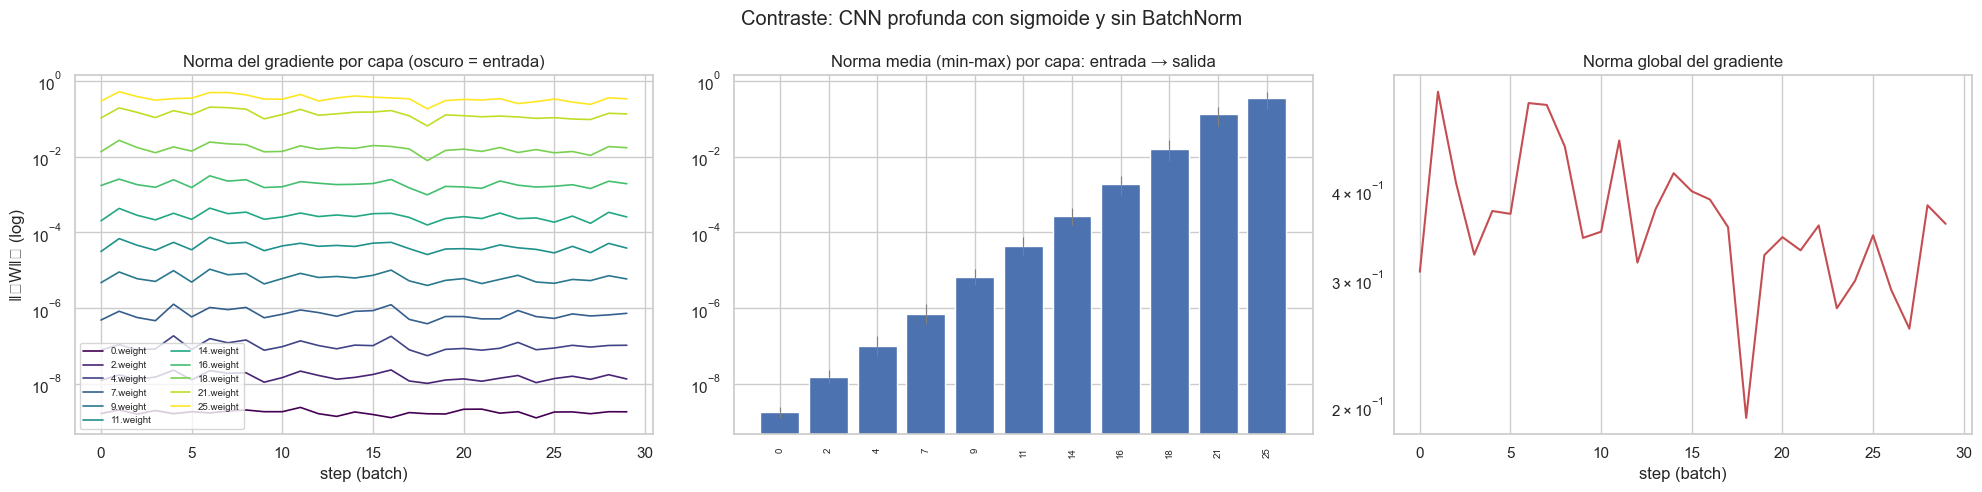

,primera capa,última capa,ratio última/primera
CNN custom (BN+ReLU),5.33e+00,8.26e-01,1.55e-01
CNN sigmoide sin BN,1.81e-09,3.42e-01,1.89e+08


In [19]:
RUN_GRADIENT_CONTRAST = True

if RUN_GRADIENT_CONTRAST:
    def plain_sigmoid_cnn(depth=10, ch=32):
        layers, in_ch = [], 3
        for i in range(depth):
            layers += [nn.Conv2d(in_ch, ch, 3, padding=1), nn.Sigmoid()]
            if i % 3 == 2:
                layers.append(nn.MaxPool2d(2))
            in_ch = ch
        return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                             nn.Linear(ch, config.NUM_CLASSES))

    set_seed(RANDOM_STATE)
    bad_model = plain_sigmoid_cnn().to(DEVICE)
    bad_monitor = GradientMonitor(bad_model, max_epochs=1, log_every=1)
    bad_opt = torch.optim.SGD(bad_model.parameters(), lr=0.01)
    crit = nn.CrossEntropyLoss()
    bad_model.train()
    for step, (x, y) in enumerate(loaders["train"]):
        if step >= 30:
            break
        bad_opt.zero_grad()
        crit(bad_model(x.to(DEVICE)), y.to(DEVICE)).backward()
        bad_monitor.log(epoch=0)
        bad_opt.step()

    fig = bad_monitor.plot("Contraste: CNN profunda con sigmoide y sin BatchNorm")
    savefig(fig, "gradientes_contraste_sigmoide"); plt.show()

    cmp = pd.DataFrame({
        "CNN custom (BN+ReLU)": grad_monitor.summary()["grad_norm_mean"].values[[0, -1]],
        "CNN sigmoide sin BN": bad_monitor.summary()["grad_norm_mean"].values[[0, -1]],
    }, index=["primera capa", "última capa"]).T
    cmp["ratio última/primera"] = cmp["última capa"] / cmp["primera capa"]
    display(cmp.style.format("{:.2e}"))

**Conclusión sobre gradientes:**

- **No hay vanishing gradients:** todas las capas reciben gradientes del
  mismo orden de magnitud. La norma media va de 5,33 en la primera
  convolución a 0,83 en la capa de clasificación: el cociente entre la capa
  con más y la capa con menos gradiente es **6,6**, menos de un orden de
  magnitud. Ninguna capa queda con gradiente casi nulo. Incluso es la
  **primera** capa la que recibe el gradiente más grande, lo opuesto al
  patrón de vanishing.
- **No hay exploding gradients:** no aparecen `NaN` ni `Inf`, y la norma
  máxima registrada en una capa fue 16,4. La norma global tiene algunos
  picos (~15-20) cerca de los steps 200 y 330, que coinciden con la subida
  del learning rate del *warm-up* de `OneCycleLR`, pero vuelve enseguida a
  su nivel (4-8) y la loss nunca diverge.
- **Contraste con la red patológica:** en la CNN de 10 convoluciones con
  sigmoide y sin BatchNorm, la primera capa recibe un gradiente de
  **1,8·10⁻⁹** contra **0,34** en la última: un cociente de **~1,9·10⁸**.
  Cada capa achica el gradiente aproximadamente un orden de magnitud (la
  derivada de la sigmoide vale como máximo 0,25), así que las primeras
  capas prácticamente no aprenden. Ese es el vanishing gradient de libro.
- **Por qué nuestra CNN no lo sufre:** (1) **ReLU** tiene derivada 1 en la
  zona activa, así que no achica el gradiente en cada capa; (2)
  **BatchNorm** re-normaliza las activaciones en cada capa y mantiene su
  escala (y la del gradiente) estable; (3) la **inicialización de He**
  arranca con varianzas adecuadas para ReLU; (4) la red es poco profunda (10
  capas con pesos). En ResNet18 el monitor muestra lo mismo (cociente 5,0;
  1,05 en `conv1` vs 1,62 en `fc`), gracias además a las *skip
  connections*.

## 6. Evaluación en test y análisis de errores

Evaluamos **una única vez** el mejor modelo (según validación) sobre el
conjunto de test.

In [20]:
y_true_c, y_pred_c, probs_c = predict(custom_model, loaders["test"], DEVICE)
test_custom = metrics_summary(y_true_c, y_pred_c)
print("CNN custom - test:", {k: round(v, 4) for k, v in test_custom.items()})
report_df(y_true_c, y_pred_c)

CNN custom - test: {'accuracy': 0.9693, 'f1_macro': 0.9687, 'f1_weighted': 0.9693}


,precision,recall,f1-score,support
AnnualCrop,0.9931,0.9567,0.9745,300.0000
Forest,0.9613,0.9933,0.9770,300.0000
HerbaceousVegetation,0.9493,0.9367,0.9430,300.0000
Highway,0.9840,0.9840,0.9840,250.0000
Industrial,0.9958,0.9560,0.9755,250.0000
Pasture,0.9744,0.9500,0.9620,200.0000
PermanentCrop,0.9105,0.9360,0.9231,250.0000
Residential,0.9585,1.0000,0.9788,300.0000
River,0.9685,0.9840,0.9762,250.0000
SeaLake,1.0000,0.9867,0.9933,300.0000


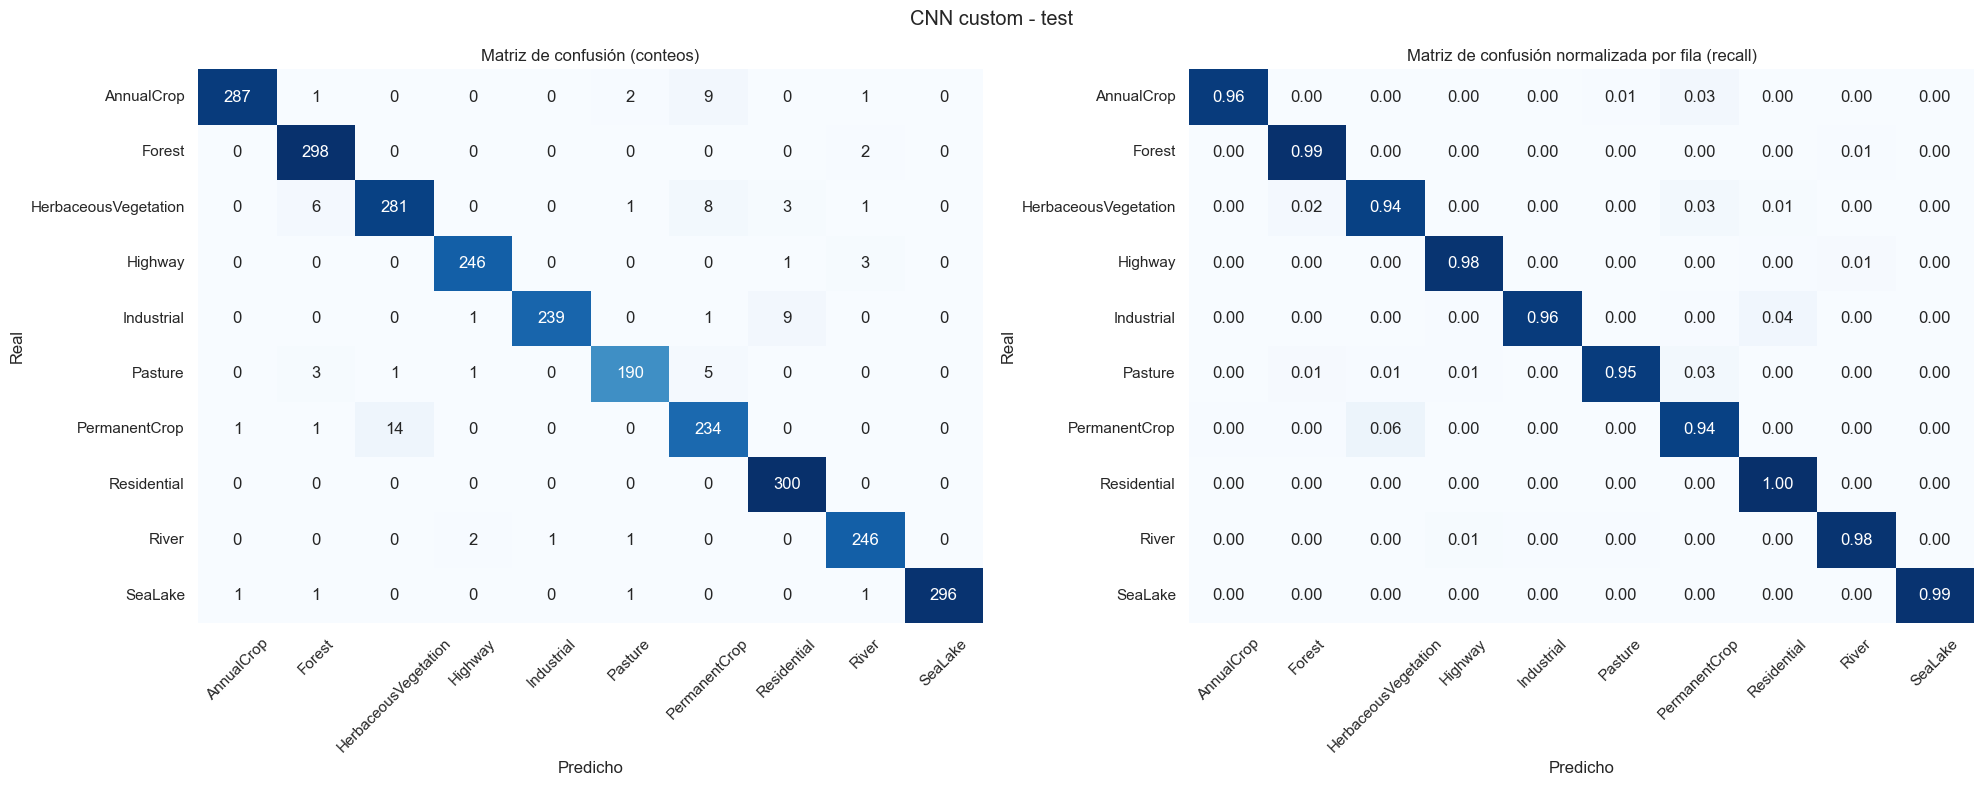

,real,predicho,n_errores,pct_de_la_clase_real
0,PermanentCrop,HerbaceousVegetation,14,0.0560
1,Industrial,Residential,9,0.0360
2,AnnualCrop,PermanentCrop,9,0.0300
3,HerbaceousVegetation,PermanentCrop,8,0.0267
4,HerbaceousVegetation,Forest,6,0.0200
5,Pasture,PermanentCrop,5,0.0250
6,Pasture,Forest,3,0.0150
7,Highway,River,3,0.0120


In [21]:
fig, cm_custom = plot_confusion_matrix(y_true_c, y_pred_c, title="CNN custom - test")
savefig(fig, "confusion_cnn_custom"); plt.show()

conf_custom = top_confusions(cm_custom, k=8)
conf_custom

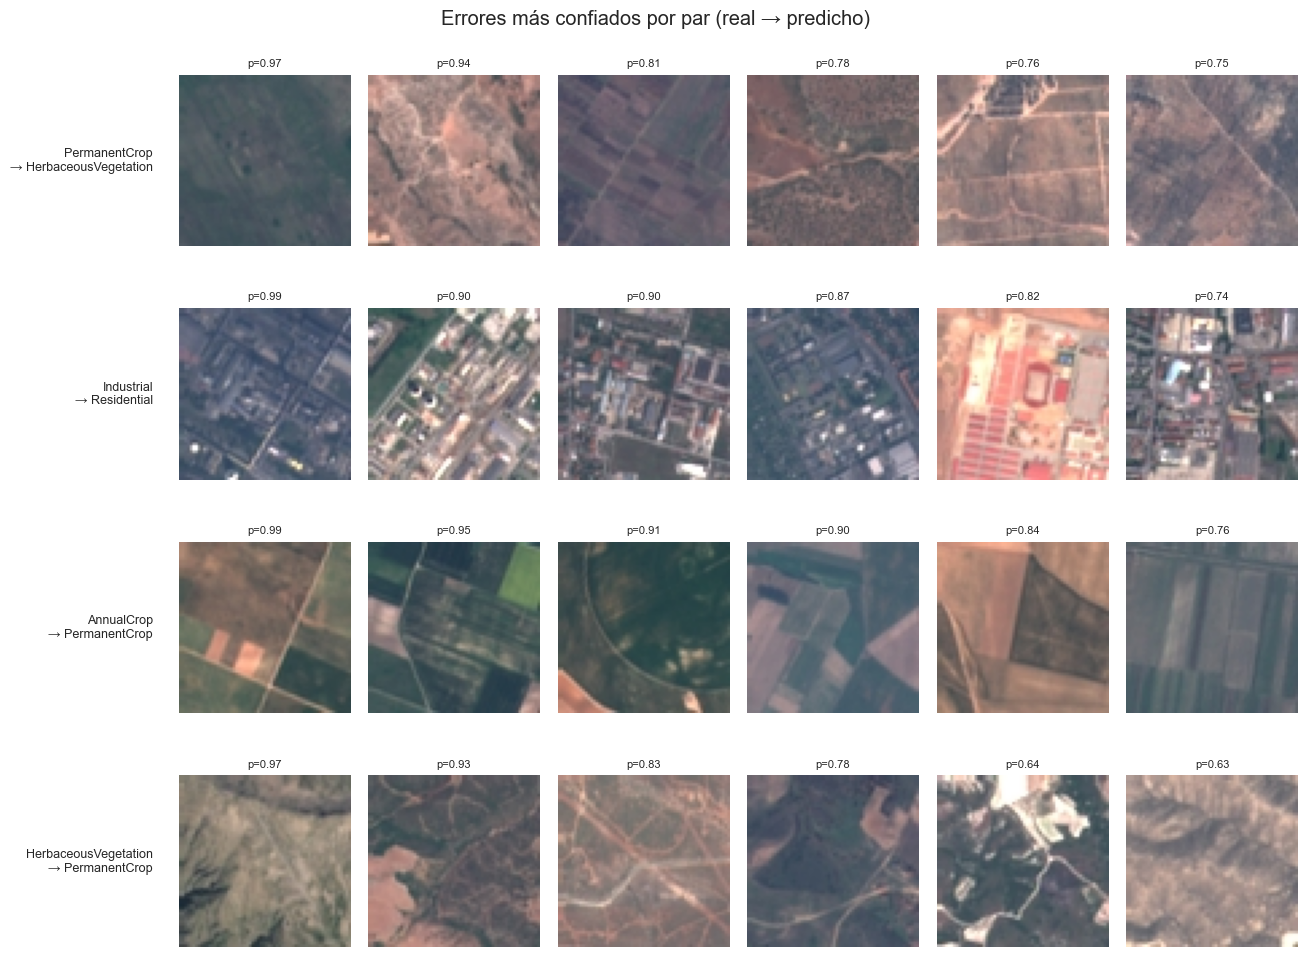

In [22]:
test_ds_vis = data.EuroSATDataset(splits["test"], eval_tf)
pairs = list(conf_custom[["real", "predicho"]].head(4).itertuples(index=False, name=None))
fig = plot_misclassified(test_ds_vis, y_true_c, y_pred_c, probs_c,
                         EUROSAT_MEAN, EUROSAT_STD, pairs=pairs, n_per_pair=6)
if fig is not None:
    savefig(fig, "errores_cnn_custom"); plt.show()

**Análisis de las confusiones más frecuentes:**

La CNN custom logra **96,93% de accuracy y 0,969 de F1-macro** en test.
Solo comete 83 errores sobre 2.700 imágenes, y se concentran en pocos
pares:

| Real → Predicho | Errores | % de la clase real |
|---|---|---|
| `PermanentCrop` → `HerbaceousVegetation` | 14 | 5,6% |
| `Industrial` → `Residential` | 9 | 3,6% |
| `AnnualCrop` → `PermanentCrop` | 9 | 3,0% |
| `HerbaceousVegetation` → `PermanentCrop` | 8 | 2,7% |
| `HerbaceousVegetation` → `Forest` | 6 | 2,0% |
| `Pasture` → `PermanentCrop` | 5 | 2,5% |

- **El grupo vegetal es la principal fuente de error.** `PermanentCrop`
  (F1 0,923) y `HerbaceousVegetation` (F1 0,943) son las dos clases con
  peor desempeño, y 5 de los 6 pares más confundidos son entre coberturas
  vegetales. Como vimos en el EDA, `AnnualCrop` y `PermanentCrop` tienen el
  mismo color medio. Mirando los ejemplos mal clasificados: los
  `PermanentCrop` que la red llama `HerbaceousVegetation` son en su mayoría
  zonas **secas y de vegetación rala**, en las que no se distinguen las
  filas de plantación; y los `AnnualCrop` que llama `PermanentCrop` son
  parcelas con **patrones de líneas paralelas** (surcos), que es justamente
  la textura típica de viñedos y frutales. Distinguir un cultivo anual de
  uno permanente es en el fondo una cuestión **temporal** (fenología a lo
  largo del año), información que una sola imagen RGB no contiene.
- **`Industrial` → `Residential` (9 errores):** son zonas urbanas densas con
  edificios chicos o mezcla de usos. Entre los errores aparecen, por
  ejemplo, un predio deportivo o educativo grande y barrios con galpones
  intercalados: a 10 m/píxel no hay forma de saber el uso del edificio. La
  asimetría es notable: `Residential` tiene **recall 1,00** (nunca se
  confunde), así que la red tiende a "absorber" en `Residential` los casos
  urbanos dudosos.
- **`Highway` ↔ `River` se confundió mucho menos de lo esperado:** solo 3
  `Highway` → `River` y 2 `River` → `Highway`. El color resuelve la
  ambigüedad de forma: el agua es más oscura y azulada que el asfalto.
- **Clases fáciles:** `SeaLake` (F1 0,993), `Highway` (0,984), `Residential`
  (0,979) y `Forest` (0,977), con colores y texturas homogéneos y
  característicos.
- **Errores semánticamente razonables:** casi no hay confusiones entre
  grupos dispares (por ejemplo, ningún `SeaLake` → `Industrial`). Los
  errores ocurren entre clases visual y semánticamente vecinas, lo que
  indica que la red aprendió una representación con sentido. Varios de los
  errores "muy confiados" (p > 0,9) se ven ambiguos incluso a simple vista,
  y algunos podrían ser **ruido de etiquetado o recortes mixtos**.

## 7. Espacio latente

Extraemos los features **justo antes de la capa de clasificación final**
(input de la última `nn.Linear`, capturado con un *forward hook*): para la
CNN custom es el embedding de **128 dimensiones**. Lo proyectamos a 2D con:

- **PCA**: proyección lineal; muestra la estructura global, pero no puede
  "desenrollar" variedades no lineales.
- **t-SNE**: preserva vecindarios locales (buena para ver clusters), pero las
  distancias entre clusters y su tamaño **no** son interpretables.
- **UMAP**: también no lineal, más rápido que t-SNE y suele preservar mejor
  la estructura global.

Como cuantificación complementaria calculamos el **silhouette score**
usando las clases reales como clusters (≈1: clusters compactos y separados;
≈0: solapados). Como **baseline** proyectamos también los **píxeles
crudos**: así vemos cuánto de la separabilidad la "construye" la red.

Features latentes (test): (2700, 128)


C:\Users\ASUS\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Proyecciones calculadas en 27.3s


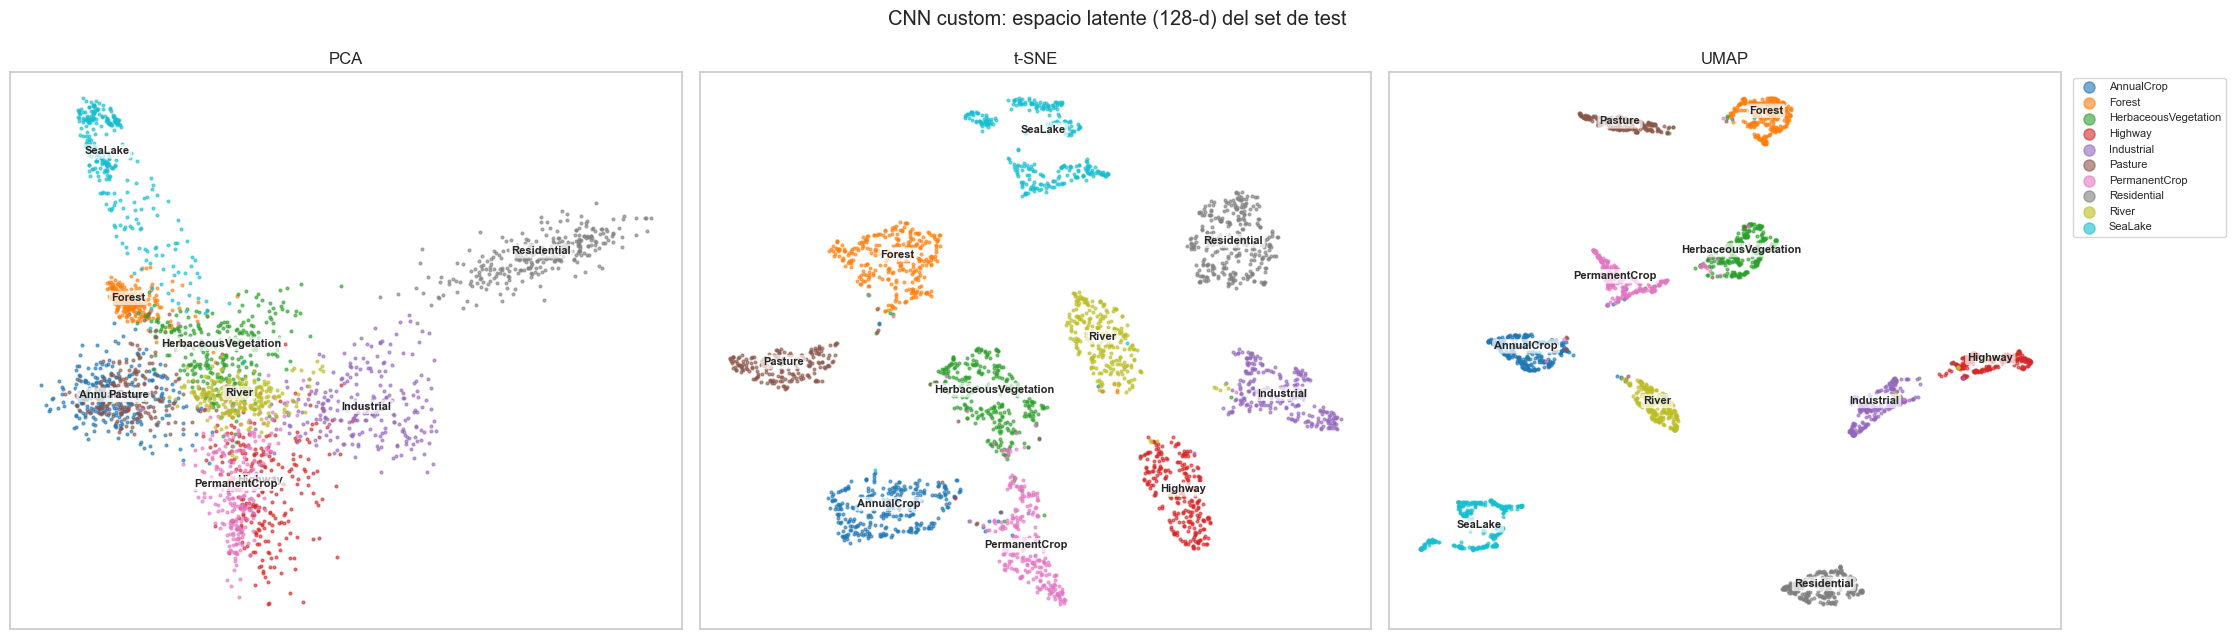

In [23]:
feats_c, labels_c = extract_features(custom_model, loaders["test"], DEVICE)
print("Features latentes (test):", feats_c.shape)

t0 = time.perf_counter()
emb_custom = {
    "PCA": project(feats_c, "pca"),
    "t-SNE": project(feats_c, "tsne"),
    "UMAP": project(feats_c, "umap"),
}
print(f"Proyecciones calculadas en {time.perf_counter() - t0:.1f}s")

fig = plot_embeddings(emb_custom, labels_c, title="CNN custom: espacio latente (128-d) del set de test")
savefig(fig, "latente_cnn_custom"); plt.show()

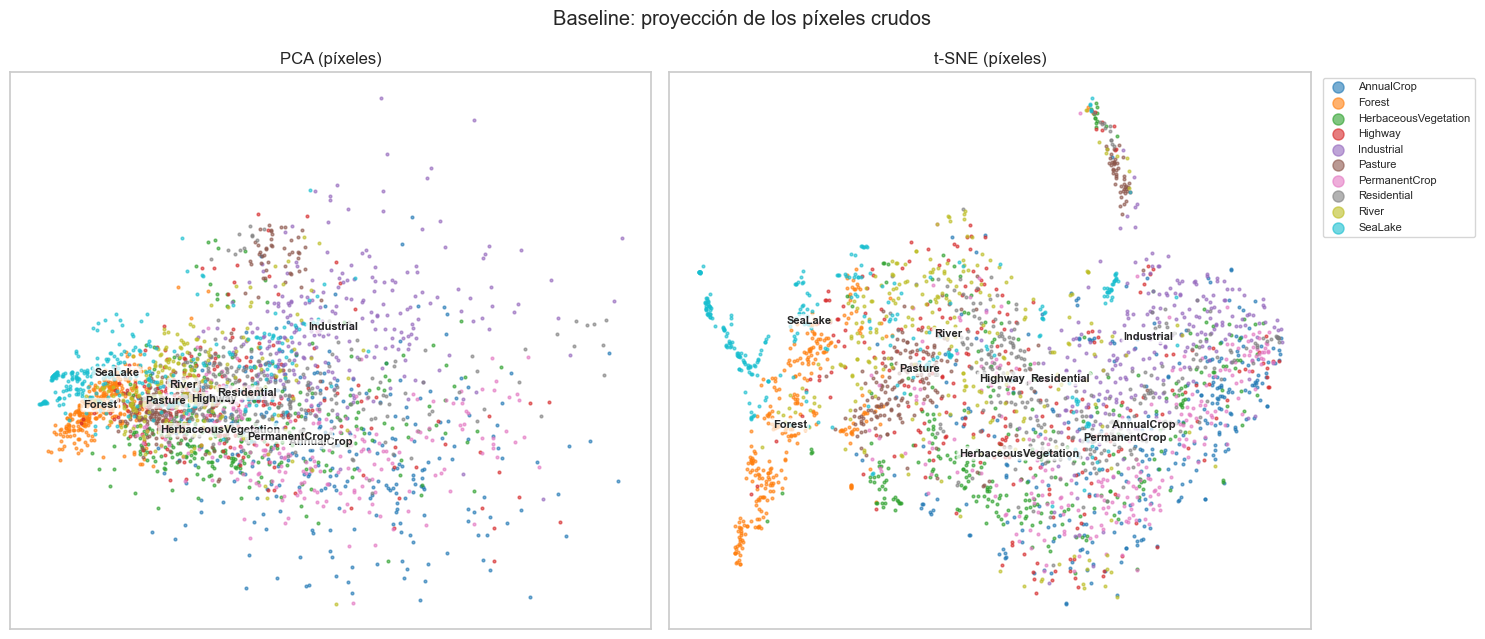

,espacio,silhouette
0,latente (128-d),0.5071
1,PCA 2D (latente),0.2748
2,t-SNE 2D (latente),0.6183
3,UMAP 2D (latente),0.7091
4,píxeles crudos (12288-d),-0.1079
5,t-SNE 2D (píxeles),-0.1406


In [24]:
# Baseline: los mismos métodos sobre los píxeles crudos (3x64x64 = 12288-d)
X_raw, y_raw = raw_pixels(loaders["test"])
emb_raw = {"PCA (píxeles)": project(X_raw, "pca"), "t-SNE (píxeles)": project(X_raw, "tsne")}
fig = plot_embeddings(emb_raw, y_raw, title="Baseline: proyección de los píxeles crudos")
savefig(fig, "latente_pixeles"); plt.show()

sep = pd.concat([
    separability_scores(feats_c, labels_c, {f"{k} 2D (latente)": v for k, v in emb_custom.items()}),
    separability_scores(X_raw, y_raw, {"t-SNE 2D (píxeles)": emb_raw["t-SNE (píxeles)"]})
        .replace({"espacio": {f"latente ({X_raw.shape[1]}-d)": f"píxeles crudos ({X_raw.shape[1]}-d)"}}),
], ignore_index=True)
sep

C:\Users\ASUS\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


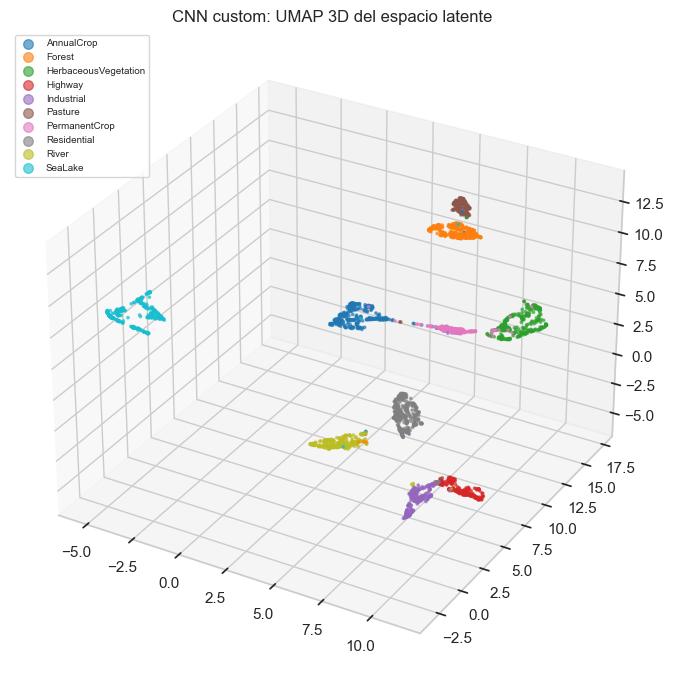

In [25]:
# Vista 3D (UMAP con 3 componentes)
emb3d = project(feats_c, "umap", n_components=3)
fig = plot_embedding_3d(emb3d, labels_c, title="CNN custom: UMAP 3D del espacio latente")
savefig(fig, "latente_cnn_custom_3d"); plt.show()

**Análisis del espacio latente:**

- **Las clases forman clusters claramente distinguibles antes de la capa
  final.** En t-SNE y UMAP aparecen 10 grupos compactos y bien separados,
  uno por clase. Cuantitativamente, el silhouette es **0,51 en el espacio
  latente de 128 dimensiones**, 0,62 en la proyección t-SNE y 0,71 en
  UMAP. Esto explica la alta accuracy: la capa final es solo un
  clasificador lineal sobre este embedding, y con clusters así de separados
  la frontera de decisión es fácil.
- **Los solapamientos coinciden con la matriz de confusión.** En t-SNE,
  `PermanentCrop` queda pegado a `HerbaceousVegetation` y a `AnnualCrop`, con
  algunos puntos sueltos de una clase dentro del cluster de la otra; e
  `Industrial` tiene puntos que se acercan a `Residential`. Son exactamente
  los pares más confundidos de la sección 6.
- **Estructura semántica:** PCA, que preserva mejor la geometría global,
  muestra el agrupamiento esperado. Las coberturas vegetales (`AnnualCrop`,
  `Pasture`, `HerbaceousVegetation`, `PermanentCrop`, `Forest`) se
  superponen en el centro, mientras que `Residential` y `SeaLake` se
  despegan en direcciones propias (las dos son las más distintas por color y
  textura). Con solo dos componentes lineales el silhouette de PCA es 0,27:
  la separación entre clases es **no lineal** y necesita más dimensiones.
- **La red construye la separabilidad:** proyectando los **píxeles crudos**
  el silhouette es **negativo** (−0,11 en el espacio original y −0,14 en
  t-SNE), es decir, las clases están completamente mezcladas. Las clases
  no son separables en el espacio de entrada; son las capas convolucionales
  las que transforman la imagen en una representación donde sí lo son.

## 8. Transfer Learning: ResNet18 preentrenada en ImageNet

Elegimos **ResNet18**: es una arquitectura clásica, liviana (11M de
parámetros) y con *skip connections*, que garantizan un buen flujo de
gradientes aunque descongelemos toda la red.

**Adaptación a EuroSAT:**

- Reemplazamos la capa final `fc` (1000 clases de ImageNet) por una
  `Linear(512 → 10)` inicializada al azar.
- Normalizamos con la **media/desvío de ImageNet** (son las estadísticas con
  las que fueron entrenados los filtros) y usamos la misma augmentation que
  en la CNN custom.
- Resolución: `TL_IMG_SIZE = 64` (nativa de EuroSAT) para que la
  comparación de tiempo por época sea justa. Subir a 224 (resolución de
  ImageNet) suele mejorar algo la accuracy a costa de ~12× más cómputo.

**Dos estrategias** (`build_resnet18(trainable=...)`):

1. **Solo últimas capas** (`trainable="layer4"`): congelamos todo el
   backbone salvo el último bloque residual y la cabeza. Se entrenan menos
   parámetros y cada época es más barata (no hay que calcular gradientes de
   las primeras capas).
2. **Fine-tuning completo** (`trainable="all"`) con **learning rates
   discriminativos**: `1e-4` para el backbone (ajustar sin destruir lo
   aprendido en ImageNet) y `1e-3` para la cabeza nueva.

Hay un *domain shift* entre ImageNet (fotos de objetos tomadas de costado) y
EuroSAT (texturas cenitales), pero los filtros de las primeras capas (bordes,
colores, texturas) son genéricos y se transfieren bien.

In [26]:
tl_train_tf, tl_eval_tf = data.build_transforms(
    config.IMAGENET_MEAN, config.IMAGENET_STD, img_size=TL_IMG_SIZE, augment=True
)
tl_loaders = data.make_dataloaders(splits, tl_train_tf, tl_eval_tf, batch_size=BATCH_SIZE)


def train_resnet(trainable, name, lr_backbone=1e-4, lr_head=1e-3, monitor=False):
    set_seed(RANDOM_STATE)
    model = build_resnet18(pretrained=PRETRAINED, trainable=trainable).to(DEVICE)
    print(f"{name} - parámetros:", count_params(model))
    groups = resnet_param_groups(model, lr_backbone=lr_backbone, lr_head=lr_head)
    opt = torch.optim.AdamW(groups, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt, max_lr=[g["lr"] for g in groups], epochs=EPOCHS_TL,
        steps_per_epoch=len(tl_loaders["train"]), pct_start=0.2,
    )
    gm = GradientMonitor(model, max_epochs=GRAD_MONITOR_EPOCHS,
                         log_every=1 if SMOKE_TEST else 10) if monitor else None
    hist, _ = fit(model, tl_loaders, opt, DEVICE, epochs=EPOCHS_TL,
                  scheduler=sched, grad_monitor=gm, name=name)
    torch.save(model.state_dict(), config.MODELS_DIR / f"{name.replace(' ', '_')}.pt")
    hist.to_csv(config.OUTPUTS_DIR / f"history_{name.replace(' ', '_')}.csv", index=False)
    return model, hist, gm

### 8.1 ResNet18 descongelando solo `layer4` + `fc`

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\ASUS/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:02<00:00, 22.6MB/s]


ResNet18 layer4+fc - parámetros: {'total': 11181642, 'trainable': 8398858}
[ResNet18 layer4+fc] epoch  1/10 | train loss 1.3638 acc 0.5746 | val loss 0.4639 acc 0.8535 | lr 5.23e-04 | 27.8s
[ResNet18 layer4+fc] epoch  2/10 | train loss 0.3295 acc 0.8930 | val loss 0.2492 acc 0.9211 | lr 1.00e-03 | 14.1s
[ResNet18 layer4+fc] epoch  3/10 | train loss 0.2159 acc 0.9272 | val loss 0.2079 acc 0.9280 | lr 9.61e-04 | 14.3s
[ResNet18 layer4+fc] epoch  4/10 | train loss 0.1795 acc 0.9383 | val loss 0.1916 acc 0.9363 | lr 8.53e-04 | 14.4s
[ResNet18 layer4+fc] epoch  5/10 | train loss 0.1555 acc 0.9451 | val loss 0.1697 acc 0.9420 | lr 6.90e-04 | 14.3s
[ResNet18 layer4+fc] epoch  6/10 | train loss 0.1344 acc 0.9540 | val loss 0.1603 acc 0.9480 | lr 4.99e-04 | 14.7s
[ResNet18 layer4+fc] epoch  7/10 | train loss 0.1176 acc 0.9588 | val loss 0.1687 acc 0.9437 | lr 3.07e-04 | 14.3s
[ResNet18 layer4+fc] epoch  8/10 | train loss 0.1065 acc 0.9632 | val loss 0.1532 acc 0.9496 | lr 1.46e-04 | 14.5s
[ResN

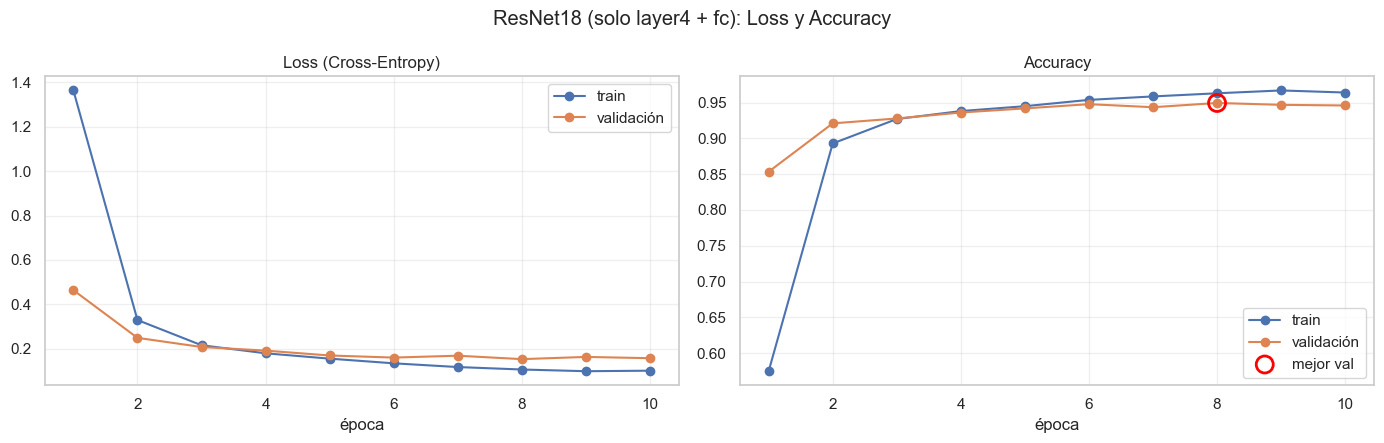

In [27]:
resnet_l4, hist_l4, _ = train_resnet("layer4", "ResNet18 layer4+fc")
fig = plot_history(hist_l4, "ResNet18 (solo layer4 + fc): Loss y Accuracy")
savefig(fig, "curvas_resnet_layer4"); plt.show()

### 8.2 ResNet18 con fine-tuning completo

ResNet18 fine-tuning - parámetros: {'total': 11181642, 'trainable': 11181642}
[ResNet18 fine-tuning] epoch  1/10 | train loss 1.2690 acc 0.6017 | val loss 0.3327 acc 0.8980 | lr 5.23e-04 | 16.3s
[ResNet18 fine-tuning] epoch  2/10 | train loss 0.2369 acc 0.9228 | val loss 0.2199 acc 0.9250 | lr 1.00e-03 | 14.5s
[ResNet18 fine-tuning] epoch  3/10 | train loss 0.1445 acc 0.9516 | val loss 0.1348 acc 0.9533 | lr 9.61e-04 | 14.5s
[ResNet18 fine-tuning] epoch  4/10 | train loss 0.1140 acc 0.9615 | val loss 0.1346 acc 0.9550 | lr 8.53e-04 | 14.3s
[ResNet18 fine-tuning] epoch  5/10 | train loss 0.0954 acc 0.9670 | val loss 0.1336 acc 0.9552 | lr 6.90e-04 | 14.6s
[ResNet18 fine-tuning] epoch  6/10 | train loss 0.0827 acc 0.9712 | val loss 0.1175 acc 0.9591 | lr 4.99e-04 | 14.2s
[ResNet18 fine-tuning] epoch  7/10 | train loss 0.0660 acc 0.9783 | val loss 0.1081 acc 0.9624 | lr 3.07e-04 | 14.4s
[ResNet18 fine-tuning] epoch  8/10 | train loss 0.0570 acc 0.9797 | val loss 0.1092 acc 0.9641 | lr 1.4

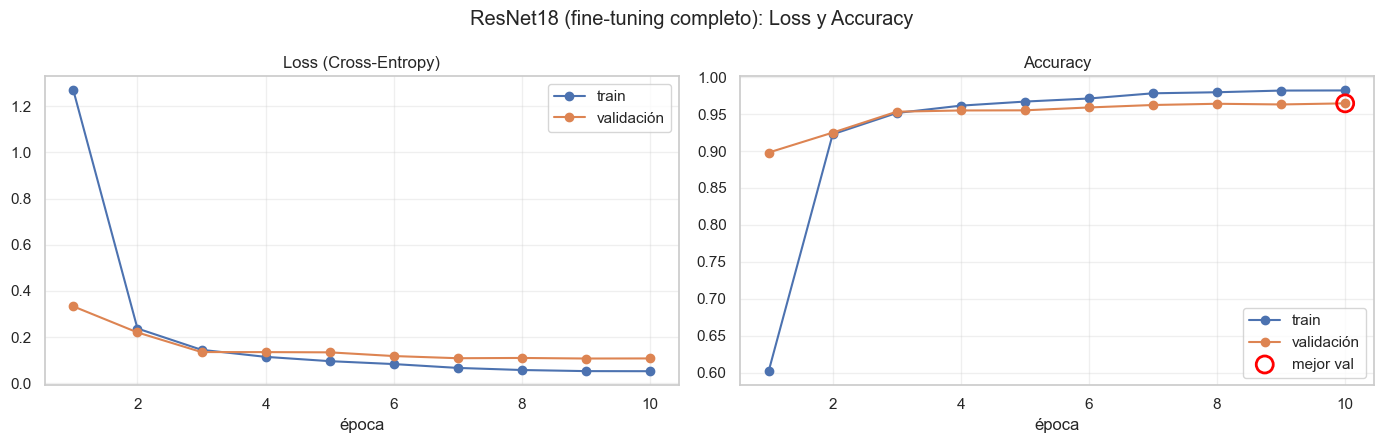

In [28]:
resnet_ft, hist_ft, gm_ft = train_resnet("all", "ResNet18 fine-tuning", monitor=True)
fig = plot_history(hist_ft, "ResNet18 (fine-tuning completo): Loss y Accuracy")
savefig(fig, "curvas_resnet_finetuning"); plt.show()

c:\Users\ASUS\Documents\Universidad\TD6\TP3\tp3_eurosat\src\eurosat_cnn\gradients.py:183: UserWarning: Glyph 8711 (\N{NABLA}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\ASUS\Documents\Universidad\TD6\TP3\tp3_eurosat\src\eurosat_cnn\gradients.py:183: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_5988\215396079.py:15: UserWarning: Glyph 8711 (\N{NABLA}) missing from font(s) Arial.
  fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
C:\Users\ASUS\AppData\Local\Temp\ipykernel_5988\215396079.py:15: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
C:\Users\ASUS\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8711 (\N{NABLA}) missing fr

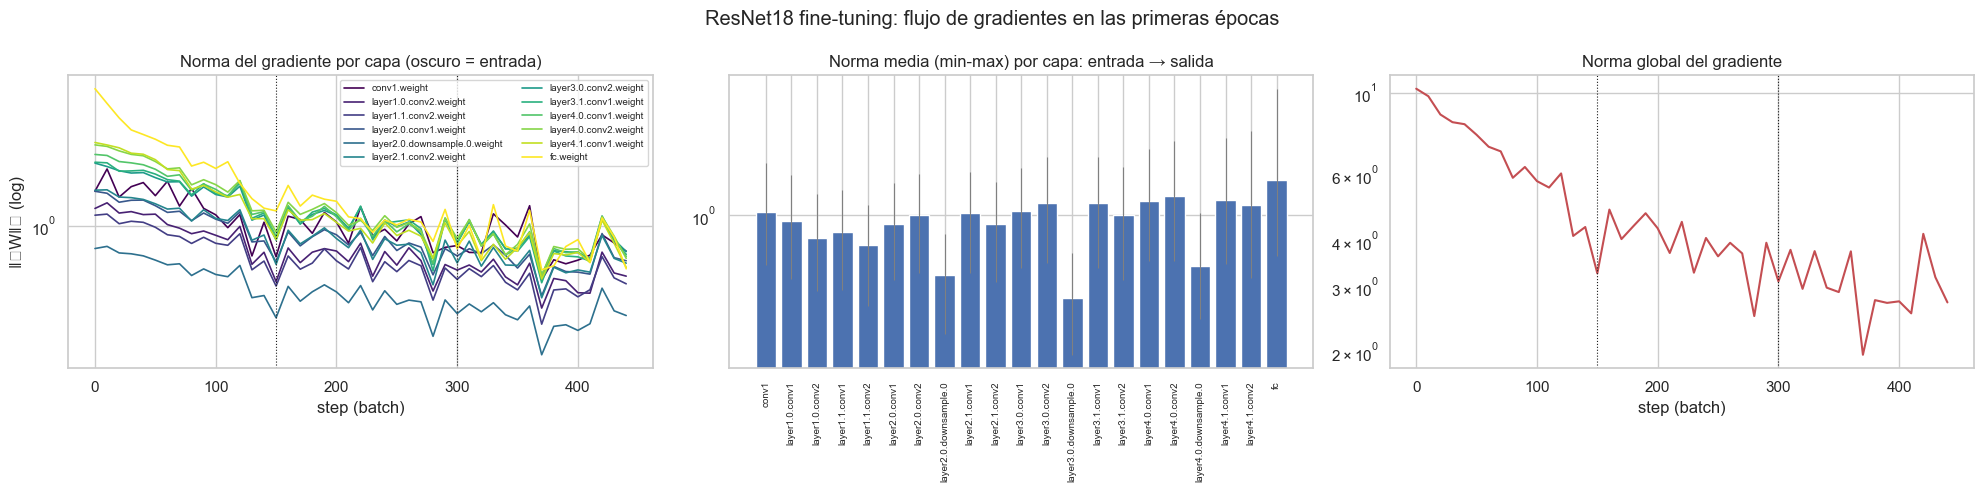

hay_nan_o_inf                              False
capas_con_grad_casi_nulo (<1e-06)             []
max_norma_registrada                      5.7121
explosion (>100)                           False
ratio_max/min_entre_capas                 5.0294
desbalance_fuerte (>1000)                  False
norma_media_primera_capa (conv1.weight)   1.0512
norma_media_ultima_capa (fc.weight)       1.6185
Name: diagnóstico, dtype: object

In [29]:
# Flujo de gradientes en el fine-tuning: las skip connections deberían
# mantener normas comparables entre las primeras y las últimas capas.
fig = gm_ft.plot("ResNet18 fine-tuning: flujo de gradientes en las primeras épocas")
savefig(fig, "gradientes_resnet_finetuning"); plt.show()
pd.Series(gm_ft.diagnose(), name="diagnóstico")

### 8.3 Evaluación en test de los modelos de transfer learning

In [30]:
results_tl = {}
for name, model in [("ResNet18 layer4+fc", resnet_l4), ("ResNet18 fine-tuning", resnet_ft)]:
    yt, yp, pr = predict(model, tl_loaders["test"], DEVICE)
    results_tl[name] = {"y_true": yt, "y_pred": yp, "probs": pr, **metrics_summary(yt, yp)}
    print(name, {k: round(results_tl[name][k], 4) for k in ("accuracy", "f1_macro")})

best_tl_name = max(results_tl, key=lambda k: results_tl[k]["f1_macro"])
best_tl = results_tl[best_tl_name]
print("\nMejor variante de transfer learning:", best_tl_name)
report_df(best_tl["y_true"], best_tl["y_pred"])

ResNet18 layer4+fc {'accuracy': 0.9559, 'f1_macro': 0.9545}
ResNet18 fine-tuning {'accuracy': 0.9733, 'f1_macro': 0.9727}

Mejor variante de transfer learning: ResNet18 fine-tuning


,precision,recall,f1-score,support
AnnualCrop,0.9964,0.9333,0.9639,300.0000
Forest,0.9645,0.9967,0.9803,300.0000
HerbaceousVegetation,0.9760,0.9500,0.9628,300.0000
Highway,0.9918,0.9720,0.9818,250.0000
Industrial,0.9959,0.9720,0.9838,250.0000
Pasture,0.9557,0.9700,0.9628,200.0000
PermanentCrop,0.9091,0.9600,0.9339,250.0000
Residential,0.9740,1.0000,0.9868,300.0000
River,0.9648,0.9880,0.9763,250.0000
SeaLake,1.0000,0.9900,0.9950,300.0000


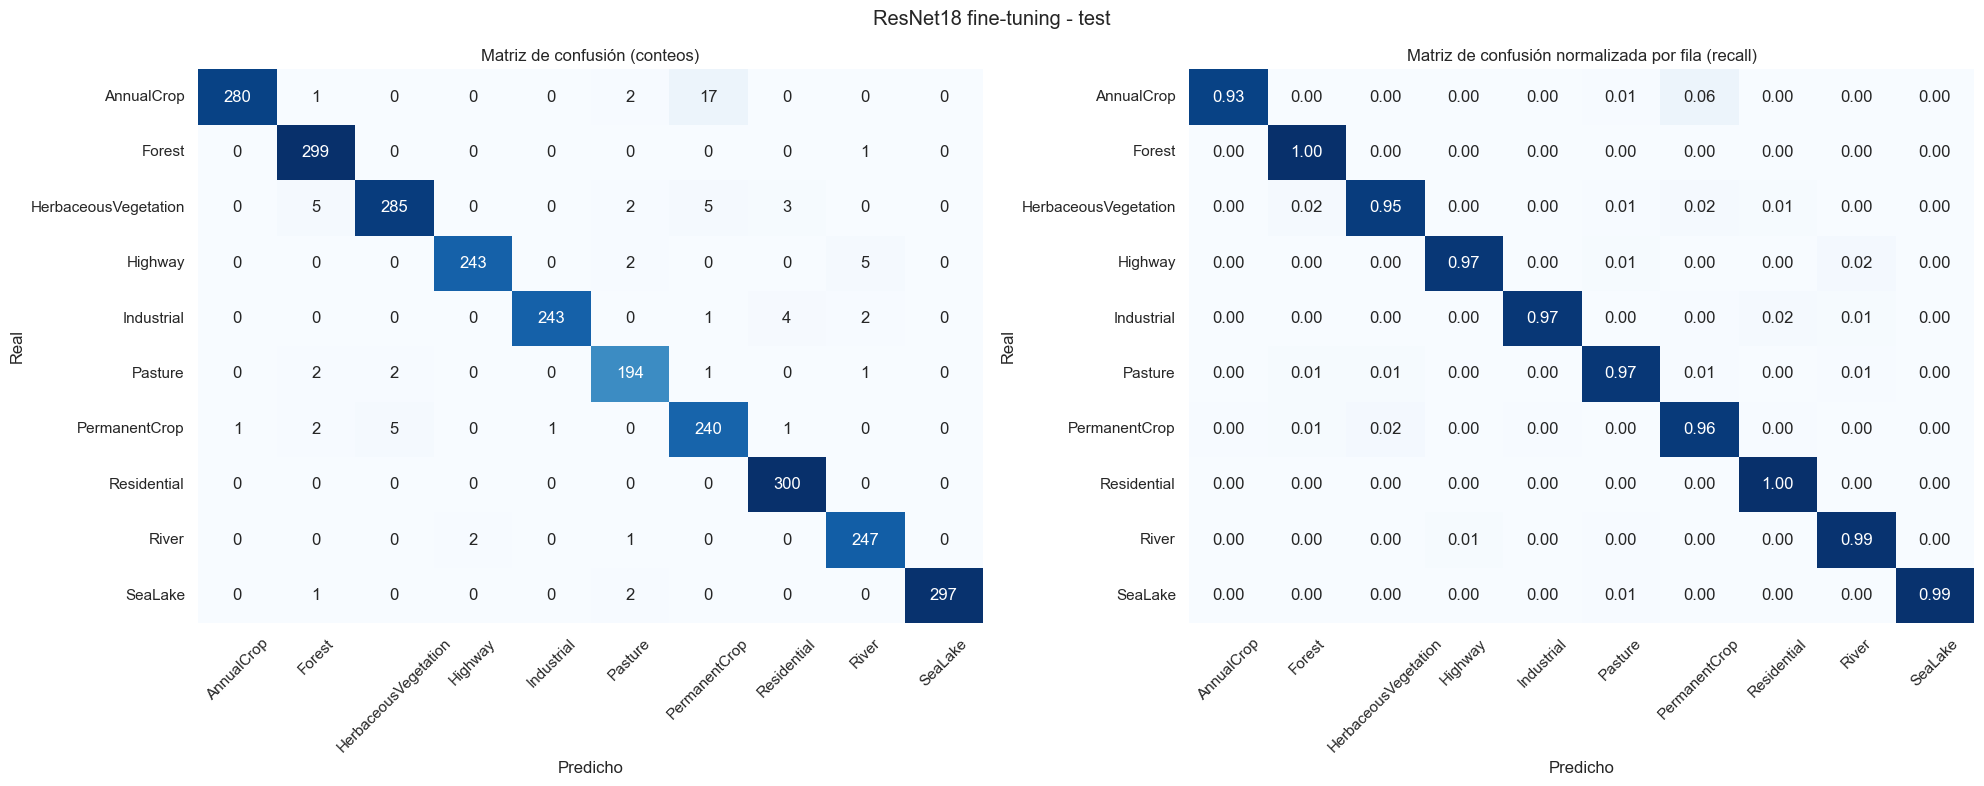

,real,predicho,errores_custom,errores_ResNet18 fine-tuning
0,PermanentCrop,HerbaceousVegetation,14,5
1,Industrial,Residential,9,4
2,AnnualCrop,PermanentCrop,9,17
3,HerbaceousVegetation,PermanentCrop,8,5
4,HerbaceousVegetation,Forest,6,5
5,Pasture,PermanentCrop,5,1
6,Pasture,Forest,3,2
7,Highway,River,3,5
8,HerbaceousVegetation,Residential,3,3
9,AnnualCrop,Pasture,2,2


In [31]:
fig, cm_tl = plot_confusion_matrix(best_tl["y_true"], best_tl["y_pred"], title=f"{best_tl_name} - test")
savefig(fig, "confusion_resnet"); plt.show()

# ¿Qué confusiones se mantienen y cuáles resuelve el transfer learning?
conf_cmp = (
    top_confusions(cm_custom, k=10).rename(columns={"n_errores": "errores_custom"})
    .merge(top_confusions(cm_tl, k=45).rename(columns={"n_errores": f"errores_{best_tl_name}"})
           [["real", "predicho", f"errores_{best_tl_name}"]],
           on=["real", "predicho"], how="left")
    .fillna({f"errores_{best_tl_name}": 0})
    .drop(columns="pct_de_la_clase_real")
)
conf_cmp

C:\Users\ASUS\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


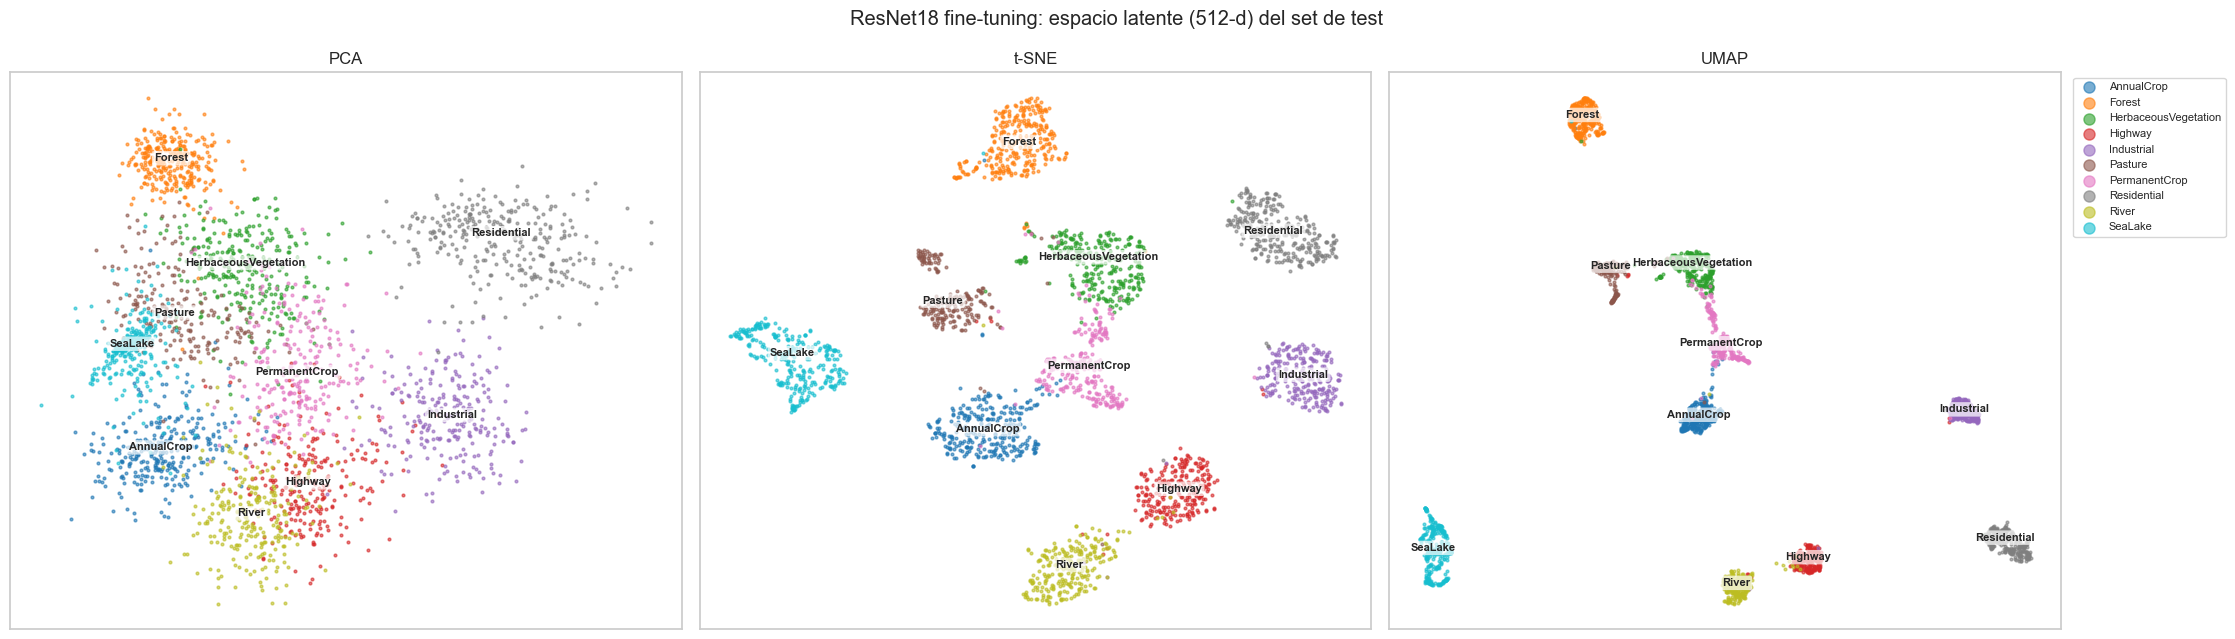

,espacio,silhouette,modelo
0,latente (128-d),0.5071,CNN custom
1,t-SNE 2D,0.6183,CNN custom
2,latente (512-d),0.2428,ResNet18 fine-tuning
3,t-SNE 2D,0.6351,ResNet18 fine-tuning


In [32]:
# Espacio latente de la mejor ResNet (512-d tras el average pooling)
best_tl_model = resnet_l4 if best_tl_name == "ResNet18 layer4+fc" else resnet_ft
feats_tl, labels_tl = extract_features(best_tl_model, tl_loaders["test"], DEVICE)
emb_tl = {"PCA": project(feats_tl, "pca"), "t-SNE": project(feats_tl, "tsne"),
          "UMAP": project(feats_tl, "umap")}
fig = plot_embeddings(emb_tl, labels_tl, title=f"{best_tl_name}: espacio latente (512-d) del set de test")
savefig(fig, "latente_resnet"); plt.show()

pd.concat([
    separability_scores(feats_c, labels_c, {"t-SNE 2D": emb_custom["t-SNE"]}).assign(modelo="CNN custom"),
    separability_scores(feats_tl, labels_tl, {"t-SNE 2D": emb_tl["t-SNE"]}).assign(modelo=best_tl_name),
], ignore_index=True)

## 9. Comparación: CNN custom vs Transfer Learning

Comparamos según lo que pide la consigna:

- **Velocidad de convergencia:** épocas (y minutos) necesarios para llegar a
  90% / 95% de accuracy de validación, y forma de las curvas.
- **Rendimiento final:** accuracy y F1-macro en test.
- **Tiempo de cómputo por época:** promedio del tiempo de entrenamiento por
  época (sin la primera, que incluye el *warm-up* de CUDA/DataLoader).

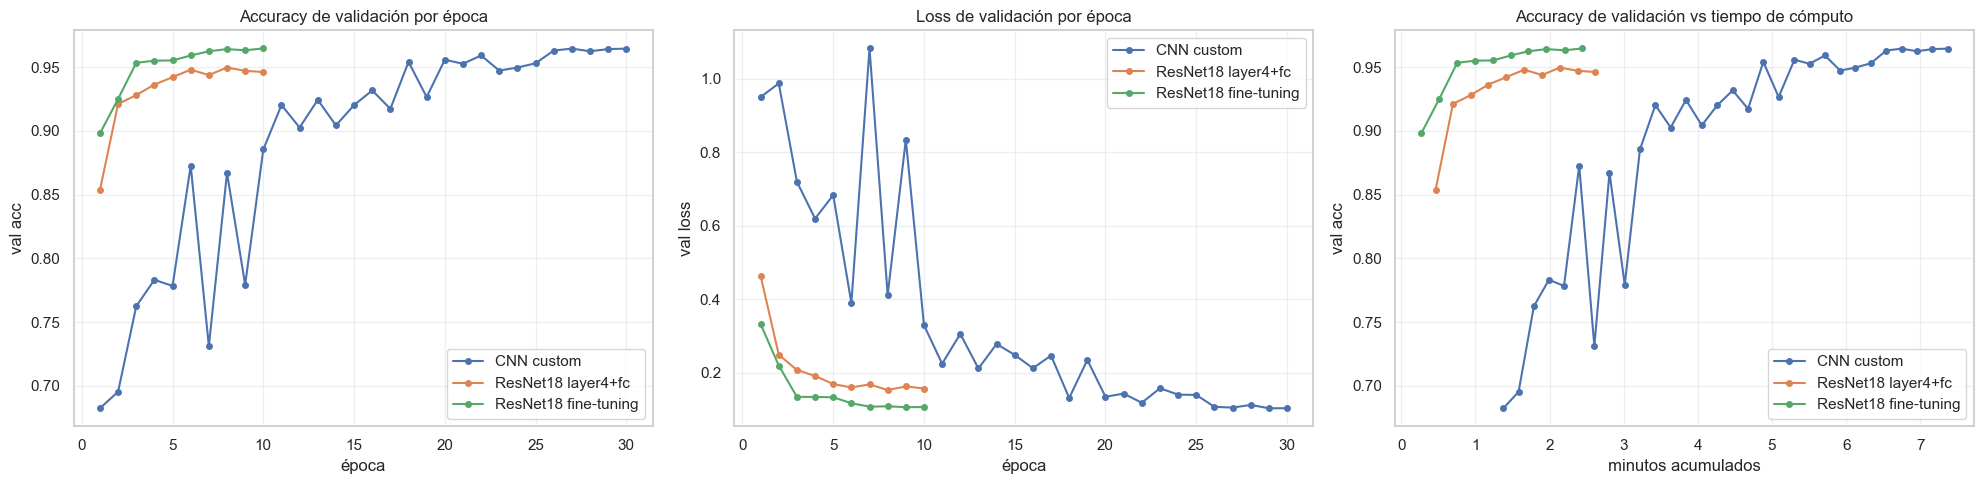

In [33]:
histories = {"CNN custom": hist_custom, "ResNet18 layer4+fc": hist_l4,
             "ResNet18 fine-tuning": hist_ft}
fig = plot_comparison(histories)
savefig(fig, "comparacion_curvas"); plt.show()

In [34]:
models_info = {"CNN custom": custom_model, "ResNet18 layer4+fc": resnet_l4,
               "ResNet18 fine-tuning": resnet_ft}
tests = {"CNN custom": test_custom, **{k: v for k, v in results_tl.items()}}

rows = []
for name, h in histories.items():
    p = count_params(models_info[name])
    t_ep = h["train_time_s"].iloc[1:] if len(h) > 1 else h["train_time_s"]
    rows.append({
        "modelo": name,
        "params_totales": p["total"],
        "params_entrenables": p["trainable"],
        "épocas": len(h),
        "val_acc_época_1": h["val_acc"].iloc[0],
        "épocas_hasta_90%": epochs_to_reach(h, 0.90),
        "épocas_hasta_95%": epochs_to_reach(h, 0.95),
        "mejor_val_acc": h["val_acc"].max(),
        "seg_por_época_train": t_ep.mean(),
        "min_totales": h["elapsed_s"].iloc[-1] / 60,
        "test_accuracy": tests[name]["accuracy"],
        "test_f1_macro": tests[name]["f1_macro"],
    })
comparison_df = pd.DataFrame(rows).set_index("modelo")
comparison_df.to_csv(config.OUTPUTS_DIR / "comparacion_modelos.csv")
comparison_df.T

modelo,CNN custom,ResNet18 layer4+fc,ResNet18 fine-tuning
params_totales,1207402.0000,11181642.0000,11181642.0000
params_entrenables,1207402.0000,8398858.0000,11181642.0000
épocas,30.0000,10.0000,10.0000
val_acc_época_1,0.6824,0.8535,0.8980
épocas_hasta_90%,11.0000,2.0000,2.0000
épocas_hasta_95%,18.0000,NaN,3.0000
mejor_val_acc,0.9644,0.9496,0.9646
seg_por_época_train,10.8049,12.4946,12.6470
min_totales,7.3673,2.6191,2.4446
test_accuracy,0.9693,0.9559,0.9733


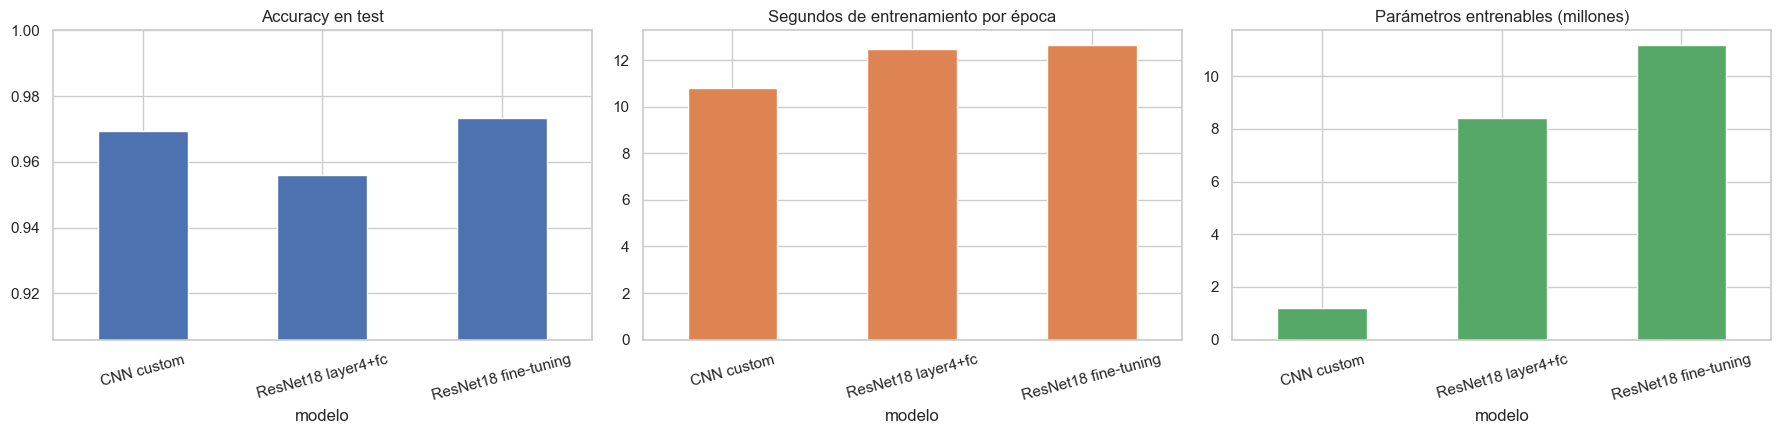

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
comparison_df["test_accuracy"].plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_ylim(max(0, comparison_df["test_accuracy"].min() - 0.05), 1)
axes[0].set_title("Accuracy en test")
comparison_df["seg_por_época_train"].plot(kind="bar", ax=axes[1], color="#DD8452")
axes[1].set_title("Segundos de entrenamiento por época")
(comparison_df["params_entrenables"] / 1e6).plot(kind="bar", ax=axes[2], color="#55A868")
axes[2].set_title("Parámetros entrenables (millones)")
for ax in axes:
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); savefig(fig, "comparacion_barras"); plt.show()

**Discusión de la comparación:**

| | CNN custom | ResNet18 `layer4`+`fc` | ResNet18 fine-tuning |
|---|---|---|---|
| Parámetros entrenables | 1,2 M | 8,4 M | 11,2 M |
| Val acc tras la 1ª época | 68,2% | 85,4% | **89,8%** |
| Épocas hasta 90% / 95% val | 11 / 18 | 2 / no llega | **2 / 3** |
| Mejor val acc | 96,44% | 94,96% | **96,46%** |
| Segundos de train por época | **10,8** | 12,5 | 12,6 |
| Minutos totales | 7,4 (30 épocas) | 2,6 (10 épocas) | **2,4** (10 épocas) |
| **Test accuracy** | 96,93% | 95,59% | **97,33%** |
| **Test F1-macro** | 0,969 | 0,954 | **0,973** |

- **Velocidad de convergencia:** es la mayor diferencia. El fine-tuning
  completo arranca en 89,8% después de **una sola época** y pasa el 95% en
  la 3ª, mientras que la CNN custom necesita 11 épocas para 90% y 18 para
  95%. Partir de filtros ya entrenados (bordes, colores, texturas) evita
  tener que aprenderlos desde cero. Las curvas de ResNet también son mucho
  más suaves: no muestran la inestabilidad de las épocas 5-10 de la CNN
  custom.
- **Rendimiento final:** el fine-tuning completo es el mejor modelo (97,33%
  en test, F1-macro 0,973). La ventaja sobre la CNN custom es chica, +0,4
  puntos (unas 11 imágenes de 2.700), y con una sola corrida por modelo (una
  sola semilla) no alcanza para afirmar que la diferencia sea significativa.
  Lo destacable es que **una CNN 9 veces más chica, entrenada desde cero,
  llega prácticamente al mismo nivel** gracias a una arquitectura adecuada
  y a augmentation pensado para el dominio.
- **Descongelar solo `layer4` rinde peor que entrenar desde cero** (95,59%):
  llega rápido a 92-93% pero se estanca en ~95% de validación. Las capas
  congeladas extraen features de ImageNet (fotos de objetos de costado, a
  224 px) que no están adaptados a texturas cenitales de 64×64 px (*domain
  shift*), y `layer4` sola no alcanza para compensarlo. Adaptar todo el
  backbone, con un LR chico (1e-4), resuelve el problema.
- **Qué errores cambia el transfer learning:** el fine-tuning reduce mucho
  las confusiones `PermanentCrop` → `HerbaceousVegetation` (14 → 5) e
  `Industrial` → `Residential` (9 → 4), pero empeora `AnnualCrop` →
  `PermanentCrop` (9 → 17). El núcleo difícil, el grupo de cultivos y
  vegetación, se mantiene en los dos modelos.
- **Tiempo de cómputo por época:** contra la intuición, una época de
  ResNet18 (11,2 M de parámetros) cuesta solo **~17% más** que una de la
  CNN custom (1,2 M): 12,6 s vs 10,8 s. Con imágenes de 64×64 la GPU no es
  el cuello de botella: lo es la **carga y augmentation de las imágenes en
  CPU**, que es igual para todos los modelos. Por la misma razón, congelar
  el backbone casi no abarata la época (12,5 s vs 12,6 s). La primera época
  de cada entrenamiento es más lenta (83 s en la custom) por el arranque de
  los procesos de carga de datos en Windows.
- **Tiempo total:** el fine-tuning alcanza su mejor resultado en
  **2,4 minutos**, contra 7,4 de la CNN custom. El gráfico *accuracy vs
  minutos acumulados* lo muestra claramente: la curva de fine-tuning está
  siempre por encima.
- **Espacio latente:** la ResNet también separa las clases en clusters
  (silhouette t-SNE 0,64 vs 0,62 de la custom). En UMAP se ve que
  `HerbaceousVegetation`, `PermanentCrop` y `AnnualCrop` forman una
  "cadena" continua, coherente con las confusiones que persisten.

## 10. Conclusiones finales

- **Datos y augmentation:** EuroSAT RGB tiene 27.000 imágenes de 64×64 casi
  balanceadas en 10 clases. Por ser imágenes cenitales, usamos
  augmentations invariantes a la orientación (flips + rotaciones de 90°,
  que cubren las 8 orientaciones sin bordes vacíos), un recorte aleatorio
  suave y un *color jitter* chico. Junto con dropout y weight decay
  eliminaron el overfitting: al final del entrenamiento, train y validación
  quedan prácticamente iguales (loss 0,092 vs 0,104).
- **CNN custom:** 4 bloques convolucionales (Conv3×3-BN-ReLU ×2 + MaxPool),
  Global Average Pooling y un embedding de 128 dimensiones, con 1,2 M de
  parámetros. Alcanza **96,93% de accuracy y 0,969 de F1-macro en test**. El
  monitoreo de gradientes confirmó un flujo sano: todas las capas en el
  mismo orden de magnitud, sin `NaN` ni explosiones, en contraste con una
  red con sigmoide y sin BatchNorm, donde el gradiente de la primera capa es
  10⁸ veces menor que el de la última. BatchNorm, ReLU y la inicialización
  de He son las responsables.
- **Errores:** se concentran en el grupo de **cultivos y vegetación**
  (`PermanentCrop`, `HerbaceousVegetation`, `AnnualCrop`, `Pasture`), con el
  mismo color y diferencias de textura sutiles o directamente temporales, y
  en **`Industrial` → `Residential`** (uso del edificio no visible a 10 m de
  resolución). Son errores entre clases semánticamente vecinas.
- **Espacio latente:** antes de la capa final las clases forman clusters
  claramente separados (silhouette 0,51 en 128-d y 0,71 en UMAP 2D), frente
  a un silhouette negativo en el espacio de píxeles. Los solapamientos
  coinciden con los pares más confundidos.
- **Transfer learning:** ResNet18 con fine-tuning completo es el mejor
  modelo (**97,33% / F1 0,973**) y converge muchísimo más rápido (90% de
  validación en la primera época, contra 11 épocas de la custom; 2,4 min vs
  7,4 min en total), con un costo por época solo ~17% mayor, porque el
  cuello de botella es la carga de datos. Descongelar solo `layer4` rinde
  peor (95,59%) por el *domain shift* entre ImageNet y las imágenes
  satelitales.
- **Recomendación:** si el objetivo es la mejor accuracy en el menor tiempo
  de entrenamiento, **fine-tuning completo de ResNet18**. Si el modelo tiene
  que ser liviano (desplegarlo en hardware limitado, o procesar millones de
  teselas a escala continental), la **CNN custom** ofrece casi el mismo
  rendimiento con 9 veces menos parámetros. En ambos casos, las mejoras más
  prometedoras para el grupo vegetal serían usar las **13 bandas
  multiespectrales** de Sentinel-2 (por ejemplo, el infrarrojo cercano,
  sensible al vigor de la vegetación) o **series temporales**, información
  que la versión RGB no tiene.